<a href="https://colab.research.google.com/github/Research-methods-group5/Hackathon_groupO/blob/main/hackathon_final_pipeline_grounded.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science Hackathon – Dataset C: COVID-19 Vaccine Acceptance → Minimum Town Cost

**Goal.** For every respondent we must decide *whether to order them a vaccine*. The town pays money in two ways, so the right metric is **expected total cost (vaccine + hospitalisation)**, not accuracy / F1.

**Pipeline**
1. Cost metric derivation (the brief gives no formula – derived from the rules, parameters are documented assumptions + sensitivity analysis)
2. Deep exploratory data analysis (quality, target, missingness, drift, association/correlation ranking)
3. Pre-processing options compared (encoding, imputation, missing-indicators, feature engineering)
4. Model comparison + hyper-parameter tuning (inner CV) + probability calibration
5. Performance analysis: repeated 5-fold CV (variance), unseen hold-out, baselines, sensitivity analysis, feature importance
6. Top-5 submissions ordered best → worst by cost

> Generative AI was used (as permitted) to research the cost structure and to help write this code. Every number in the *Assumptions* cell can be changed in one place.

In [3]:
import warnings, os, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, train_test_split,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (HistGradientBoostingClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, ExtraTreesClassifier)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, accuracy_score, f1_score, roc_curve

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

TRAIN_PATH, TEST_PATH = "dataset_C_training.csv", "dataset_C_testing.csv"

train = pd.read_csv(TRAIN_PATH); test = pd.read_csv(TEST_PATH)
TARGET, ID = "covid_vaccine", "respondent_id"
print("train", train.shape, "| test", test.shape)

train (4756, 31) | test (4749, 30)


## 1. Evaluation metric – deriving the town's cost

Rules from the brief:
* Everyone is infected (100 %), so hospitalisation risk applies to **everyone**.
* Everyone who *wants* a vaccine must get one; **if we did not order one for them we pay them the vaccine price instead** (they stay unvaccinated).
* Vaccines are posted to homes and **ruined if not used** → ordering for someone who then refuses wastes the price.
* Hospitalisation cost = P(hospitalised | person, vaccinated?) × cost per hospitalisation.

For person *i* with true acceptance *y* (1 = wants vaccine), decision *d* (1 = order), vaccine price $C_v$, hospital cost $C_h$, unvaccinated hospitalisation probability $h_i$ and vaccine effectiveness $VE$ (relative reduction in hospitalisation):

| | y=1 (accepts) | y=0 (refuses) |
|---|---|---|
| **d=1 order** (TP / FP) | $C_v + C_h\,h_i(1-VE)$ | $C_v + C_h\,h_i$ (wasted dose) |
| **d=0 don't order** (FN / TN) | $C_v + C_h\,h_i$ (cash payout) | $C_h\,h_i$ |

**Key consequence.** With acceptance probability $p_i$ the *expected-cost-optimal* rule is
$$\text{order} \iff p_i > p_i^* = \frac{C_v}{C_v + C_h\,h_i\,VE}$$
The threshold is **not 0.5**: it is low for high-risk people (e.g. 65+) where a vaccine pays for itself, and higher for low-risk people. So the modelling goal is **well-calibrated probabilities**, then this decision rule.

### Assumptions (grounded scenario - replace with your team's consensus from several AIs)
We use a **grounded** scenario built from published figures, not a best or worst case. **Given by the brief/team: vaccine price = 1,500 and hospitalisation cost = 41,000.** Everyone is infected (100 %), so the hospitalisation risk is *per infection*, not per season.
* **Vaccine effectiveness 45 %** against hospitalisation (CDC VISION/IVY 2024-25 interim estimate for adults 65+, 95 % CI about 36-53 %, measured 7-119 days after the dose). Earlier 80-90 % figures come from the early pandemic and the original variants and are not realistic now. No estimate exists for ages 18-64 because of low power, so the same value is used for all ages.
* **Hospitalisation risk by age** derived from COVID-NET season rates (per 100k: 18-49 about 39, 50-64 about 113, 65-74 about 284, 75+ about 936), converted to a per-infection risk (about 0.08 % at 18-34 up to 1.2 % at 65+). **+75 % per chronic condition.**
* **Behaviours (masks, hand washing, distancing)** are neutral on severity (multiplier 1.0): they affect acceptance (modelled from the data) but there is no solid evidence for a severity effect once infected.
* These are still assumptions (the training data has no outcomes). The **sensitivity analysis** in section 7 varies vaccine effectiveness (30-70 %) and risk (x0.5 to x3).


In [4]:
# ------------------------- ASSUMPTIONS (single place to edit) -------------------------
BASE = dict(
    C_V = 1500.0,        # price of one vaccine dose (also the cash payout if none is available)
    C_H = 41_000.0,     # average cost of one hospitalisation
    VE  = 0.45,         # GROUNDED: CDC VISION/IVY 2024-25 interim VE vs hospitalisation, adults 65+ = 45% (95% CI ~36-53%), 7-119 days post-dose
)
# GROUNDED age profile: P(hospitalised | infected, unvaccinated, 0 chronic conditions).
# Derivation: CDC COVID-NET Oct 2023-Apr 2024 hospitalisation rate per 100k (18-49 ~39, 50-64 ~113, 65-74 ~284, 75+ ~936; MMWR 73(39)),
# divided by an assumed ~35 % seasonal infection share (because here EVERYONE is infected) and by ~1.5 (average chronic-condition uplift already in the
# population rate), then rounded UP slightly for under-ascertainment. Uncertainty is roughly a factor of 2-3 either way -> see sensitivity section 7.
H_UNVAC_BY_AGE = {"18 - 34 Years": 0.0008, "35 - 44 Years": 0.0010, "45 - 54 Years": 0.0015, "55 - 64 Years": 0.0030, "65+ Years": 0.0120}
CHRONIC_MULT = 0.75     # each chronic condition adds +75 % relative risk (capped at 3). ~80 % of hospitalised adults had >=2 conditions (COVID-NET)

# Behavioural modifiers. Everyone is infected (100 % exposure at winter parties), so precautions cannot prevent infection,
# but masks / hand hygiene / avoiding crowds lower the viral dose and (modestly) severity; antivirals shorten & soften illness.
# GROUNDED: with 100 % infection there is no solid evidence that masks / hand washing / distancing change SEVERITY, so all multipliers are neutral (1.0).
# Edit a value below 1 to test a protective effect (e.g. antivirals 0.7) - the sensitivity section does not rely on them.
BEH_RR = {"behavioral_face_mask": 1.0, "behavioral_wash_hands": 1.0, "behavioral_avoidance": 1.0,
          "behavioral_large_gatherings": 1.0, "behavioral_outside_home": 1.0, "behavioral_touch_face": 1.0,
          "behavioral_antiviral_meds": 1.0}

HOSP_MODE = "age_chronic"   # "flat" | "age_chronic" | "behavioural" (age + chronic + precautions) <- default is the grounded age + chronic model
FLAT_H = 0.004              # used when HOSP_MODE == "flat"

def hosp_prob_unvaccinated(df):
    '''Per-person P(hosp | unvaccinated, infected). Built only from columns present in train AND test.'''
    if HOSP_MODE == "flat": return np.full(len(df), FLAT_H)
    base = df["age_group"].map(H_UNVAC_BY_AGE).fillna(np.mean(list(H_UNVAC_BY_AGE.values())))
    n = df["number_chronic_med_conditions"].fillna(0).clip(0, 3)
    h = base * (1 + CHRONIC_MULT * n)
    if HOSP_MODE == "behavioural":
        for col, rr in BEH_RR.items(): h = h * np.where(df[col].fillna(0) == 1, rr, 1.0)   # missing answer -> no protection assumed
    return h.clip(upper=0.5).to_numpy()

def person_cost(y, d, h, C_V=BASE["C_V"], C_H=BASE["C_H"], VE=BASE["VE"]):
    '''Vectorised cost per person. y: truth(0/1), d: order decision(0/1), h: P(hosp|unvaccinated).'''
    y, d = np.asarray(y), np.asarray(d)
    vaccine_cost = np.where(d == 1, C_V, y * C_V)                 # ordered (used or wasted) | payout if wanted but not ordered
    vaccinated   = (d == 1) & (y == 1)
    hosp_cost    = C_H * h * np.where(vaccinated, 1 - VE, 1.0)
    return vaccine_cost + hosp_cost

def total_cost(y, d, h, **kw): return person_cost(y, d, h, **kw).sum()

def optimal_threshold(h, C_V=BASE["C_V"], C_H=BASE["C_H"], VE=BASE["VE"]):
    '''Per-person probability above which ordering a vaccine minimises expected cost.'''
    return C_V / (C_V + C_H * h * VE)

def decide(p, h, **kw):                      # expected-cost-optimal decision rule
    return (np.asarray(p) > optimal_threshold(h, **kw)).astype(int)

train["h_unvac"] = hosp_prob_unvaccinated(train); test["h_unvac"] = hosp_prob_unvaccinated(test)
y_all, h_all = train[TARGET].to_numpy(), train["h_unvac"].to_numpy()

# Reference strategies on the whole training set
ref = pd.Series({
    "Oracle (knows the truth)":       total_cost(y_all, y_all, h_all),
    "Order for nobody":               total_cost(y_all, np.zeros_like(y_all), h_all),
    "Order for everybody":            total_cost(y_all, np.ones_like(y_all), h_all),
}); print((ref / len(train)).round(2).rename("cost per person ").to_frame())
print("\nOptimal threshold range across people: %.3f – %.3f" % (optimal_threshold(h_all).min(), optimal_threshold(h_all).max()))

                          cost per person 
Oracle (knows the truth)            688.33
Order for nobody                    729.64
Order for everybody                1698.21

Optimal threshold range across people: 0.676 – 0.990


## 2. Exploratory data analysis

### 2.1 Structure, quality and duplicates

In [5]:
display(train.drop(columns="h_unvac").head())
desc = pd.DataFrame({"dtype": train.drop(columns="h_unvac").dtypes.astype(str),
                     "n_unique": train.drop(columns="h_unvac").nunique(),
                     "missing": train.drop(columns="h_unvac").isna().sum(),
                     "missing_%": (train.drop(columns="h_unvac").isna().mean()*100).round(1)})
display(desc)
print("duplicate ids:", train[ID].duplicated().sum(), "| fully duplicated feature rows:",
      train.drop(columns=[ID, TARGET, "h_unvac"]).duplicated().sum())
print("Target balance:\n", train[TARGET].value_counts(normalize=True).round(3).to_string())

,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,dtype,n_unique,missing,missing_%
respondent_id,int64,4756,0,0.0
covid_concern,float64,4,12,0.3
covid_knowledge,float64,3,27,0.6
behavioral_antiviral_meds,float64,2,14,0.3
behavioral_avoidance,float64,2,27,0.6
behavioral_face_mask,float64,2,2,0.0
behavioral_wash_hands,float64,2,9,0.2
behavioral_large_gatherings,float64,2,10,0.2
behavioral_outside_home,float64,2,14,0.3
behavioral_touch_face,float64,2,21,0.4


duplicate ids: 0 | fully duplicated feature rows: 0
Target balance:
 covid_vaccine
0    0.673
1    0.327


In [6]:
FEATURES = [c for c in train.columns if c not in (ID, TARGET, "h_unvac")]
# Column typing: understand what each variable is (binary flags / ordinal scales / nominal categories)
CAT_COLS = [c for c in FEATURES if train[c].dtype == "object" or str(train[c].dtype).startswith("str")]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print("Categorical:", CAT_COLS, "\n\nNumeric / ordinal-coded:", NUM_COLS)
for c in CAT_COLS: print(f"\n{c}:", train[c].value_counts(dropna=False).to_dict())

Categorical: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector'] 

Numeric / ordinal-coded: ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

age_group: {'65+ Years': 1208, '55 - 64 Years': 992, '45 - 54 Years': 948, '18 - 34 Years': 947, '35 - 44 Years': 661}

education: {'College Graduate': 1883, 'Some College': 1222, '12 Years': 1018, '< 12 Years': 405, nan: 228}

race: {'White': 3798, 'Black': 353, 'Hispanic': 321, 'Other or Multiple': 284}

sex: {'Female': 2865, 'Male': 1891}



### 2.2 Target and missing-data patterns

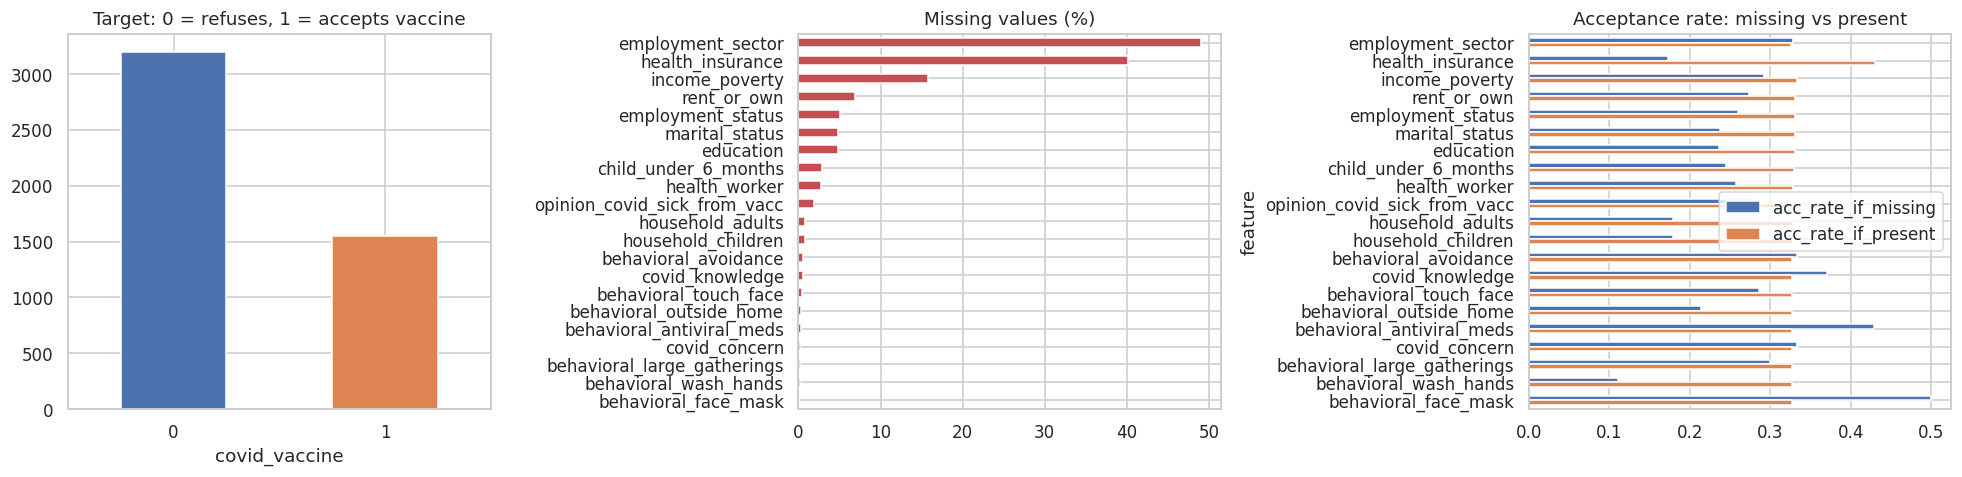

Missing indicators of health_insurance / employment_sector look informative -> keep them as features (section 3).


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
train[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color=["#4c72b0", "#dd8452"]); ax[0].set_title("Target: 0 = refuses, 1 = accepts vaccine"); ax[0].set_xticklabels(["0","1"], rotation=0)
miss = train[FEATURES].isna().mean().sort_values(ascending=False); miss = miss[miss > 0] * 100
miss.plot.barh(ax=ax[1], color="#c44e52"); ax[1].set_title("Missing values (%)"); ax[1].invert_yaxis()
# does being missing carry signal about the target?
rows = []
for c in miss.index:
    m = train[c].isna()
    rows.append((c, train.loc[m, TARGET].mean(), train.loc[~m, TARGET].mean()))
mt = pd.DataFrame(rows, columns=["feature", "acc_rate_if_missing", "acc_rate_if_present"]).set_index("feature")
mt.plot.barh(ax=ax[2]); ax[2].set_title("Acceptance rate: missing vs present"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()
print("Missing indicators of health_insurance / employment_sector look informative -> keep them as features (section 3).")

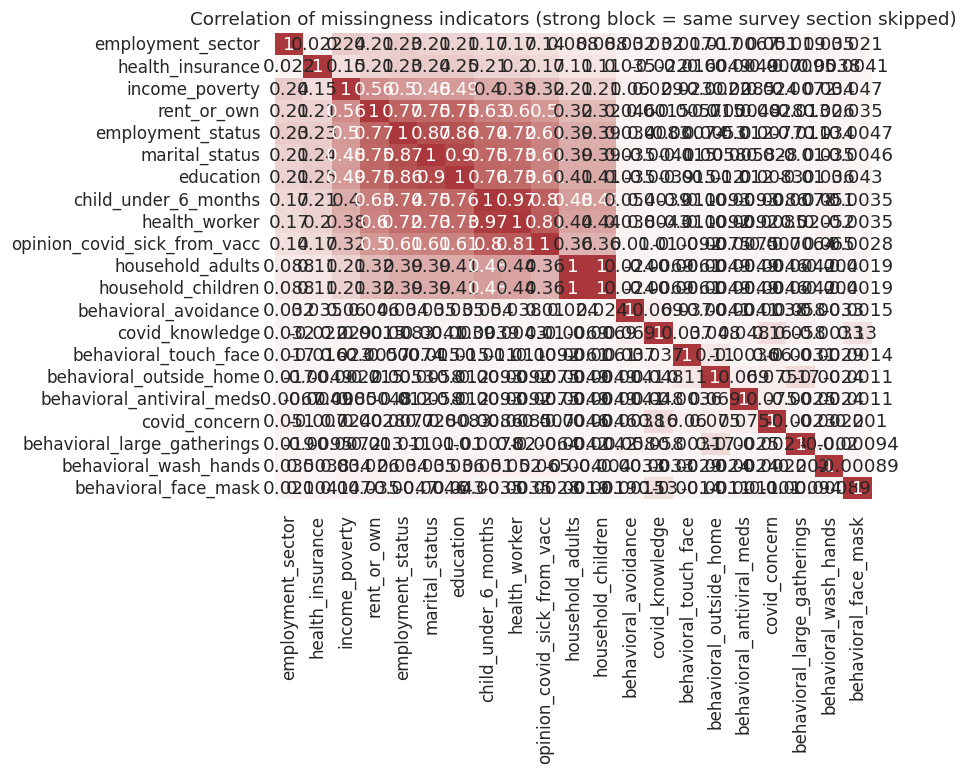

In [8]:
# Is the missingness itself structured (MAR vs MCAR)? correlation of missing-indicators
mi = train[miss.index].isna().astype(int)
plt.figure(figsize=(7, 5.5)); sns.heatmap(mi.corr(), annot=True, cmap="vlag", center=0, cbar=False)
plt.title("Correlation of missingness indicators (strong block = same survey section skipped)"); plt.show()

### 2.3 Train vs test drift (adversarial validation)

In [9]:
# If a classifier can tell train rows from test rows, the distributions differ and validation would be optimistic.
adv = pd.concat([train[FEATURES].assign(_t=0), test[FEATURES].assign(_t=1)], ignore_index=True)
adv_X = pd.get_dummies(adv.drop(columns="_t"), dummy_na=True).astype(float)
adv_auc = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=SEED), adv_X, adv["_t"],
                            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"Adversarial AUC = {roc_auc_score(adv['_t'], adv_auc):.3f}  (0.5 = identical distributions)")
shift = []
for c in FEATURES:
    a = train[c].astype(str); b = test[c].astype(str)
    ct = pd.crosstab(pd.concat([a, b]), np.r_[np.zeros(len(a)), np.ones(len(b))])
    shift.append((c, stats.chi2_contingency(ct)[1]))
print("Features with significant train/test shift (p<0.01):", [c for c, p in shift if p < 0.01] or "none")

Adversarial AUC = 0.506  (0.5 = identical distributions)
Features with significant train/test shift (p<0.01): none


### 2.4 Univariate distributions and acceptance rate by feature

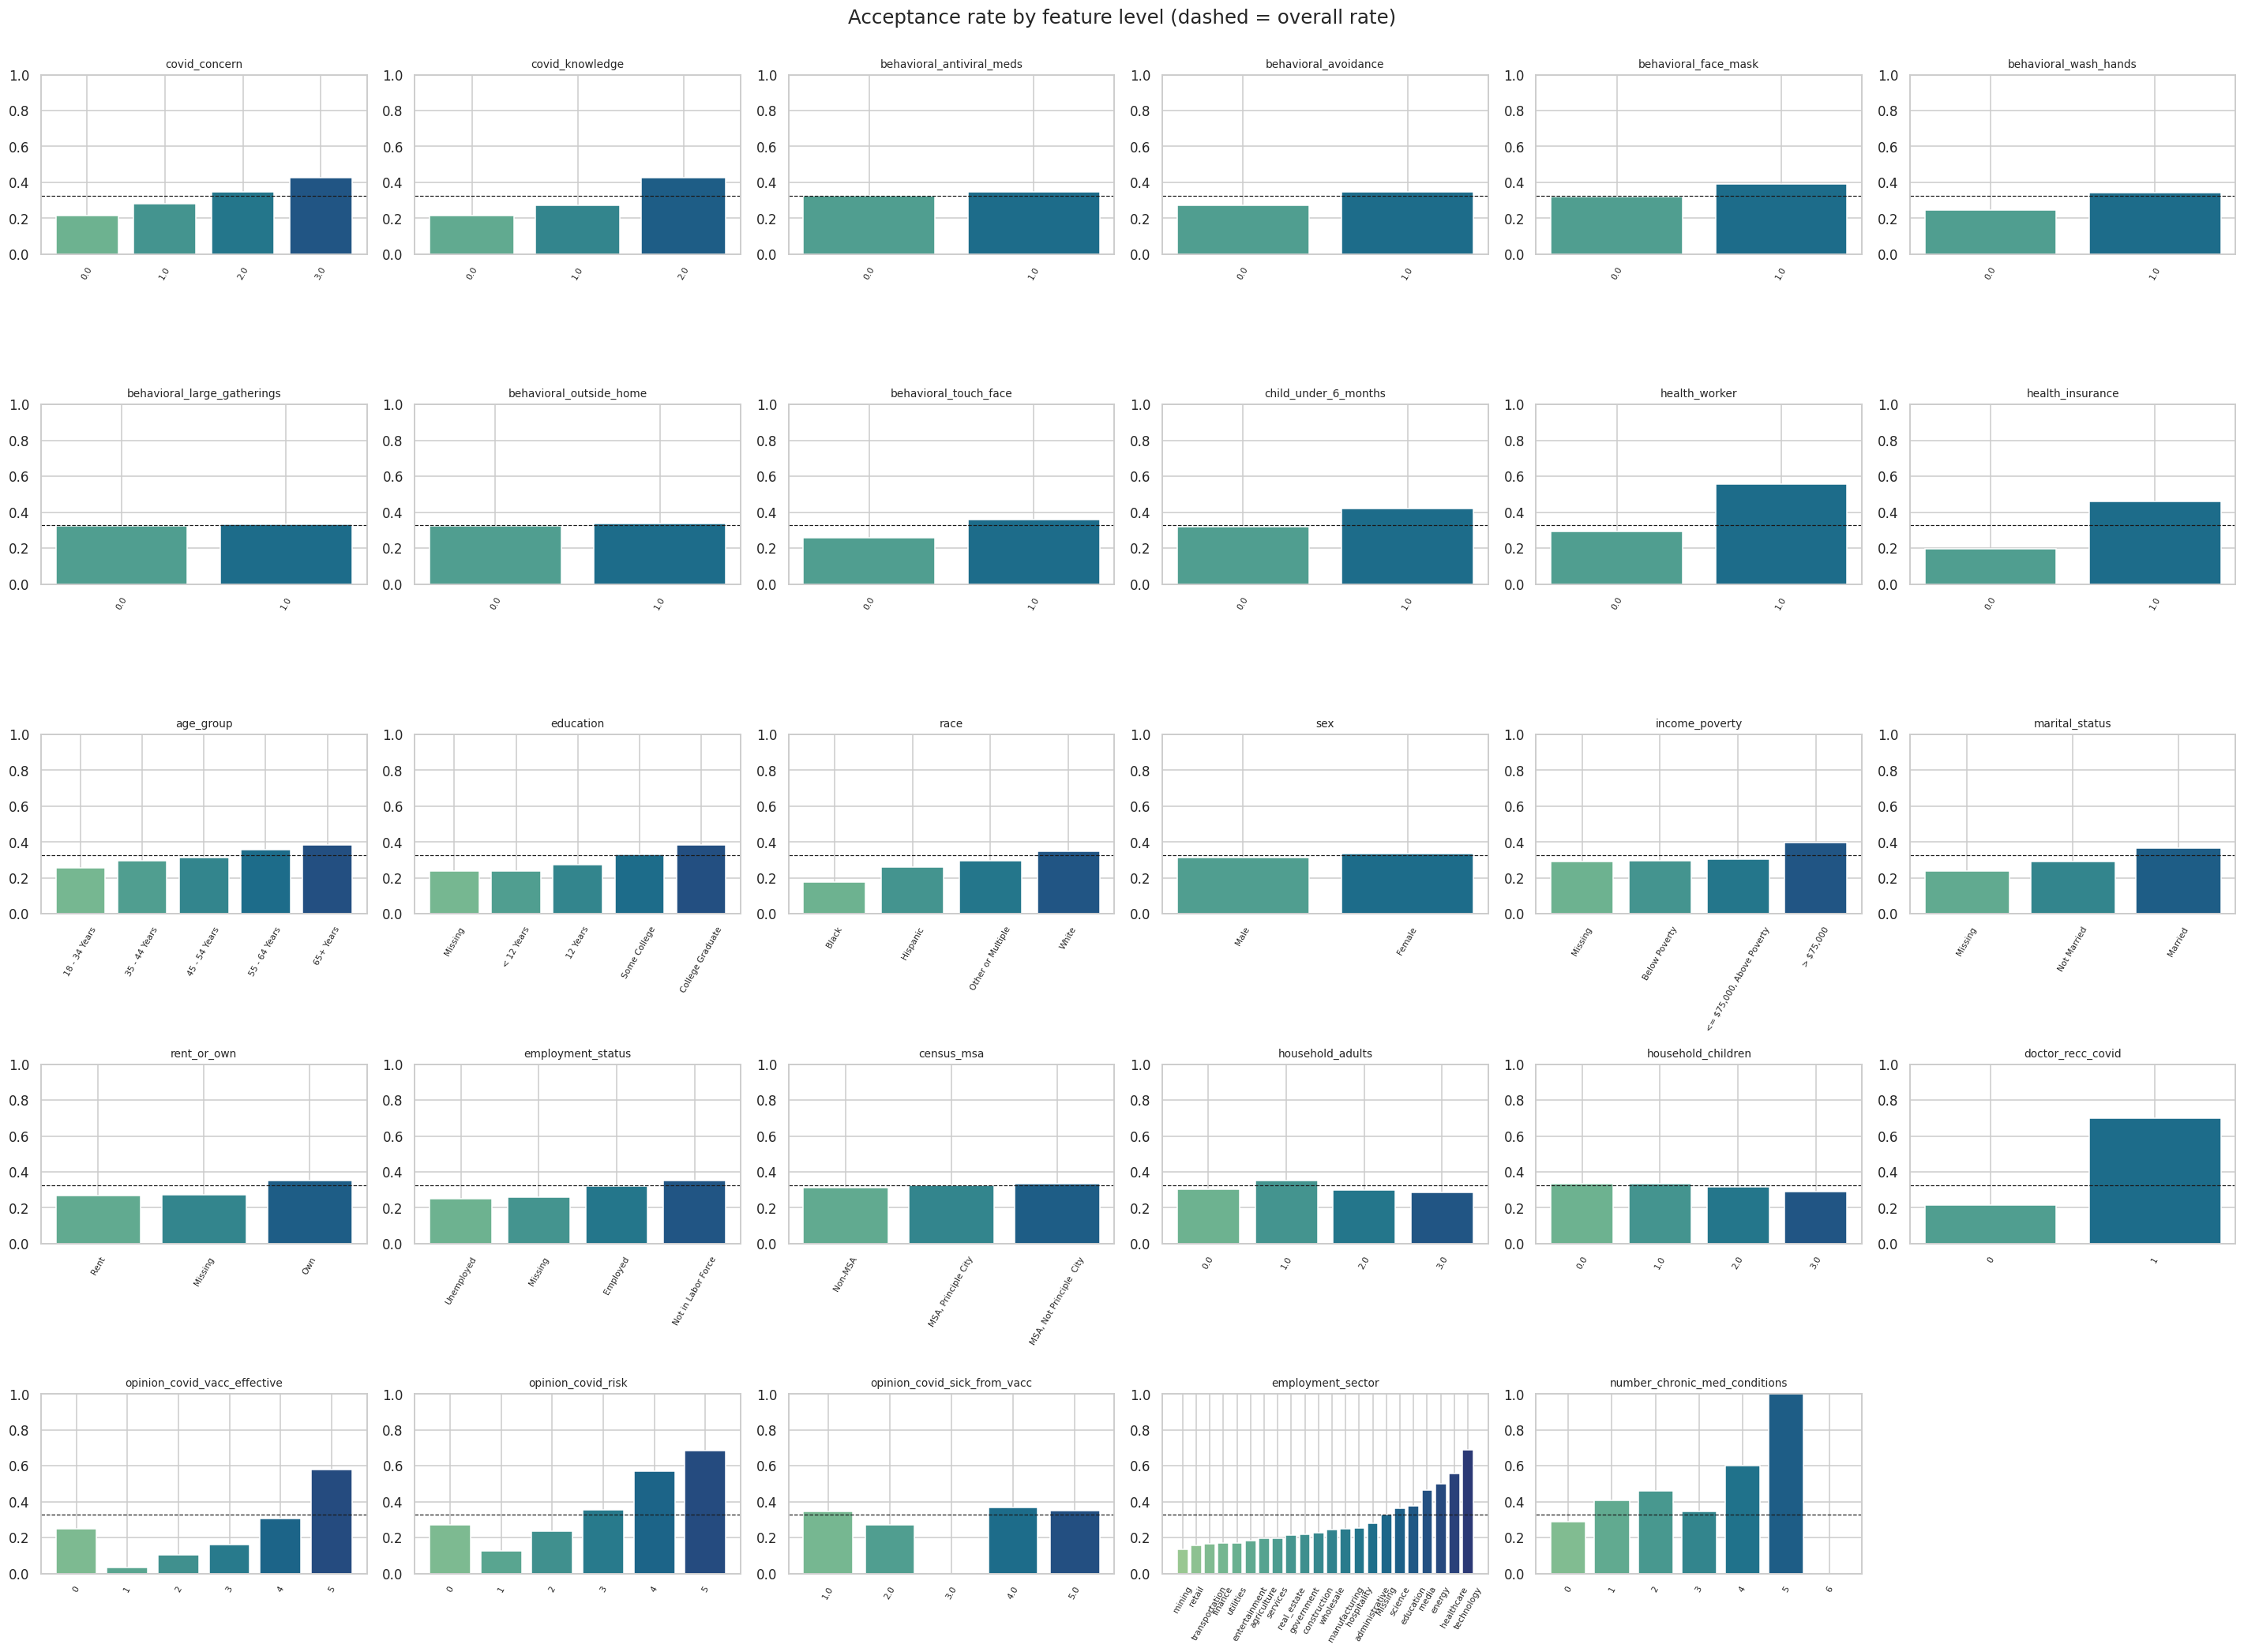

In [10]:
fig, axes = plt.subplots(5, 6, figsize=(26, 19)); axes = axes.ravel()
for i, c in enumerate(FEATURES):
    order = None
    if c in NUM_COLS: order = sorted(train[c].dropna().unique())
    d = train.assign(**{c: train[c].fillna("Missing")}) if c in CAT_COLS else train
    rate = d.groupby(c)[TARGET].agg(["mean", "size"])
    if c in CAT_COLS: rate = rate.sort_values("mean")
    axes[i].bar(rate.index.astype(str), rate["mean"], color=sns.color_palette("crest", len(rate)))
    axes[i].axhline(train[TARGET].mean(), color="k", ls="--", lw=.8)
    axes[i].set_title(c, fontsize=9); axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=60, labelsize=7)
for j in range(i + 1, len(axes)): axes[j].axis("off")
plt.suptitle("Acceptance rate by feature level (dashed = overall rate)", y=1.0, fontsize=16); plt.tight_layout(); plt.show()

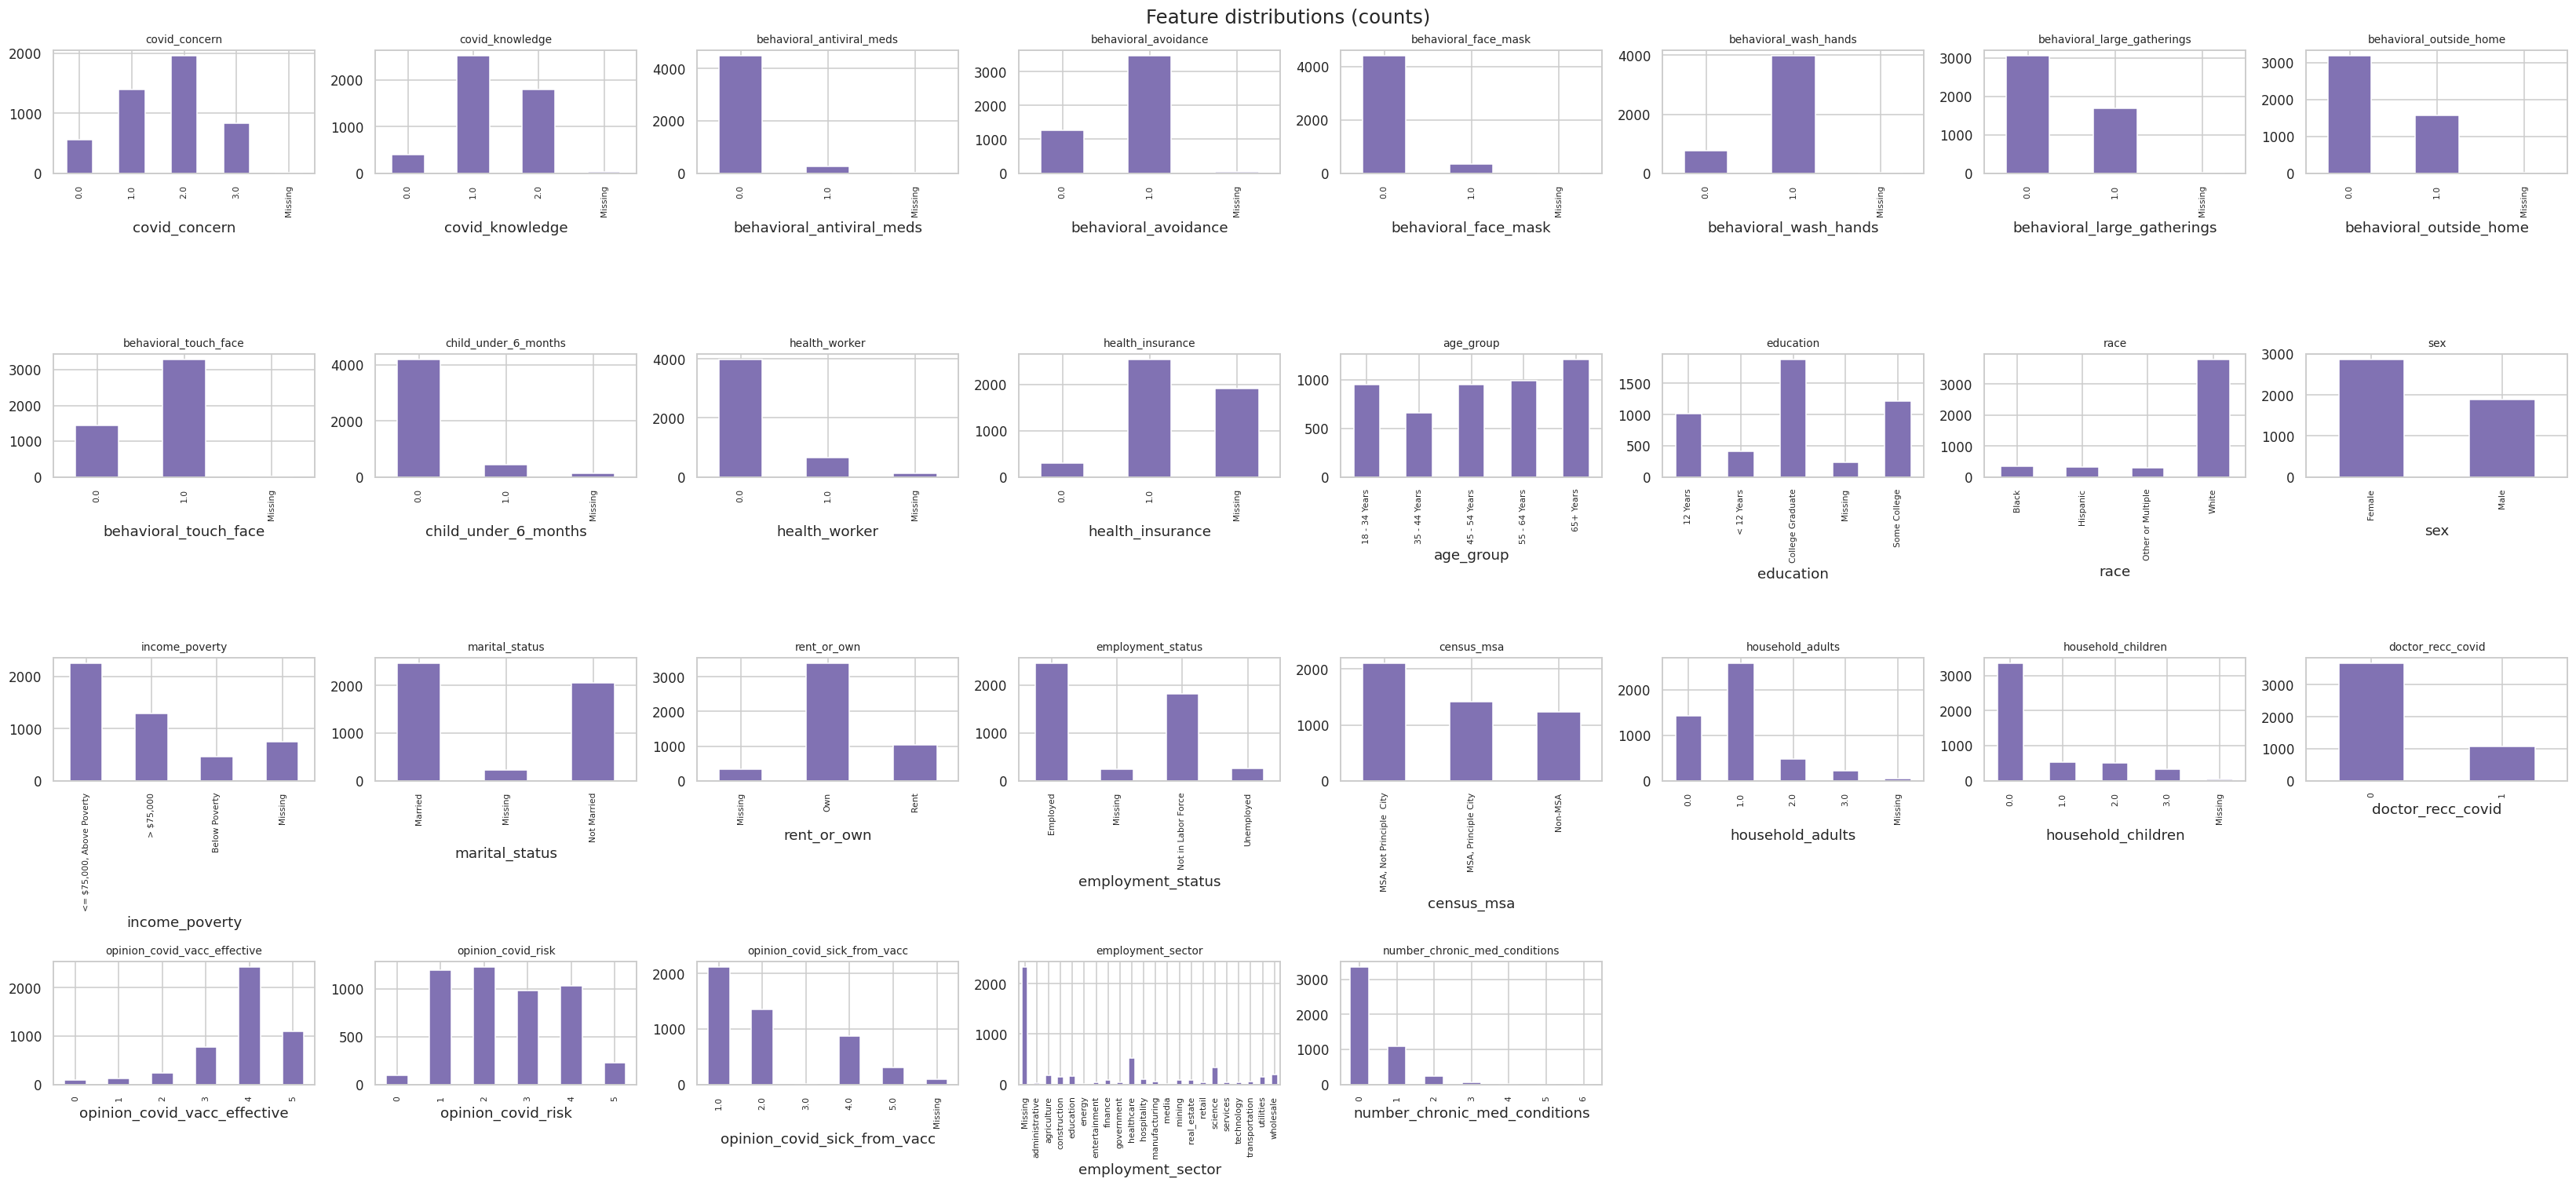

In [11]:
# Counts per level (shows which levels are rare -> unreliable)
fig, axes = plt.subplots(4, 8, figsize=(30, 14)); axes = axes.ravel()
for i, c in enumerate(FEATURES):
    train[c].fillna("Missing").astype(str).value_counts().sort_index().plot.bar(ax=axes[i], color="#8172b3")
    axes[i].set_title(c, fontsize=9); axes[i].tick_params(axis="x", labelsize=7)
for j in range(i + 1, len(axes)): axes[j].axis("off")
plt.suptitle("Feature distributions (counts)", fontsize=16); plt.tight_layout(); plt.show()

### 2.5 Which variables relate to the target? (correlation / association ranking)
The data is mostly categorical/ordinal, so Pearson alone is not enough. We combine four complementary measures:
* **Cramér's V** (bias-corrected) – association strength for categorical vs binary target
* **Mutual information** – captures non-linear relationships
* **Spearman ρ** (ordinal/binary features) – direction of the relationship
* **χ² p-value** – is it statistically distinguishable from noise?

,cramers_v,chi2_p,spearman_rho,mutual_info
feature,,,,
doctor_recc_covid,0.430200,0.000000,0.430400,0.088300
opinion_covid_risk,0.378900,0.000000,0.364500,0.073500
opinion_covid_vacc_effective,0.330700,0.000000,0.321200,0.057300
health_insurance,0.299500,0.000000,0.164600,0.003000
employment_sector,0.223400,0.000000,-0.009600,0.027100
health_worker,0.195300,0.000000,0.197200,0.018000
covid_knowledge,0.167800,0.000000,0.168400,0.014200
covid_concern,0.132000,0.000000,0.134400,0.009300
number_chronic_med_conditions,0.126300,0.000000,0.125700,0.008400


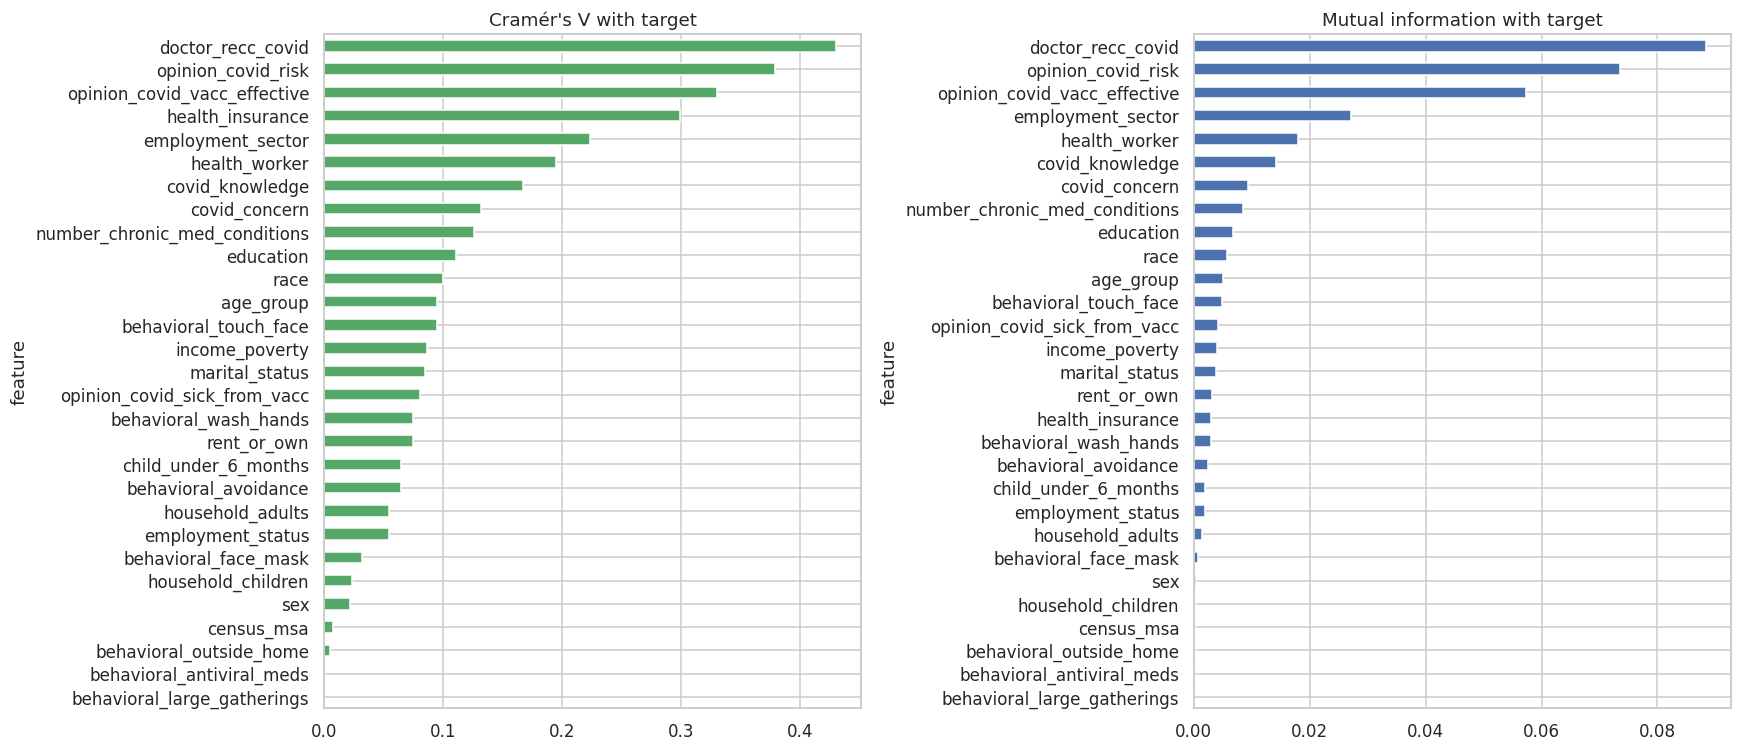

In [12]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum()
    phi2 = chi2 / n; r, k = ct.shape
    phi2c = max(0, phi2 - (k-1)*(r-1)/(n-1)); rc, kc = r-(r-1)**2/(n-1), k-(k-1)**2/(n-1)
    return np.sqrt(phi2c / max(1e-12, min(kc-1, rc-1)))

Xe = train[FEATURES].copy()
rows = []
for c in FEATURES:
    s = Xe[c].astype(object).where(Xe[c].notna(), "Missing")
    ct = pd.crosstab(s, train[TARGET]); p = stats.chi2_contingency(ct)[1]
    # Spearman on a numeric coding (ordinal codes for text columns -> only meaningful for ordered ones)
    codes = pd.Series(pd.Categorical(Xe[c]).codes, index=Xe.index) if c in CAT_COLS else Xe[c]
    rho = stats.spearmanr(codes, train[TARGET], nan_policy="omit")[0]
    rows.append((c, cramers_v(s, train[TARGET]), p, rho))
assoc = pd.DataFrame(rows, columns=["feature", "cramers_v", "chi2_p", "spearman_rho"]).set_index("feature")
Xmi = Xe.copy()
for c in Xmi: Xmi[c] = pd.Categorical(Xmi[c]).codes if c in CAT_COLS else Xmi[c].fillna(Xmi[c].median())
assoc["mutual_info"] = mutual_info_classif(Xmi, train[TARGET], discrete_features=True, random_state=SEED)
assoc = assoc.sort_values("cramers_v", ascending=False)
display(assoc.round(4).style.background_gradient(subset=["cramers_v", "mutual_info"], cmap="Greens"))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
assoc["cramers_v"].sort_values().plot.barh(ax=ax[0], color="#55a868"); ax[0].set_title("Cramér's V with target")
assoc["mutual_info"].sort_values().plot.barh(ax=ax[1], color="#4c72b0"); ax[1].set_title("Mutual information with target")
plt.tight_layout(); plt.show()

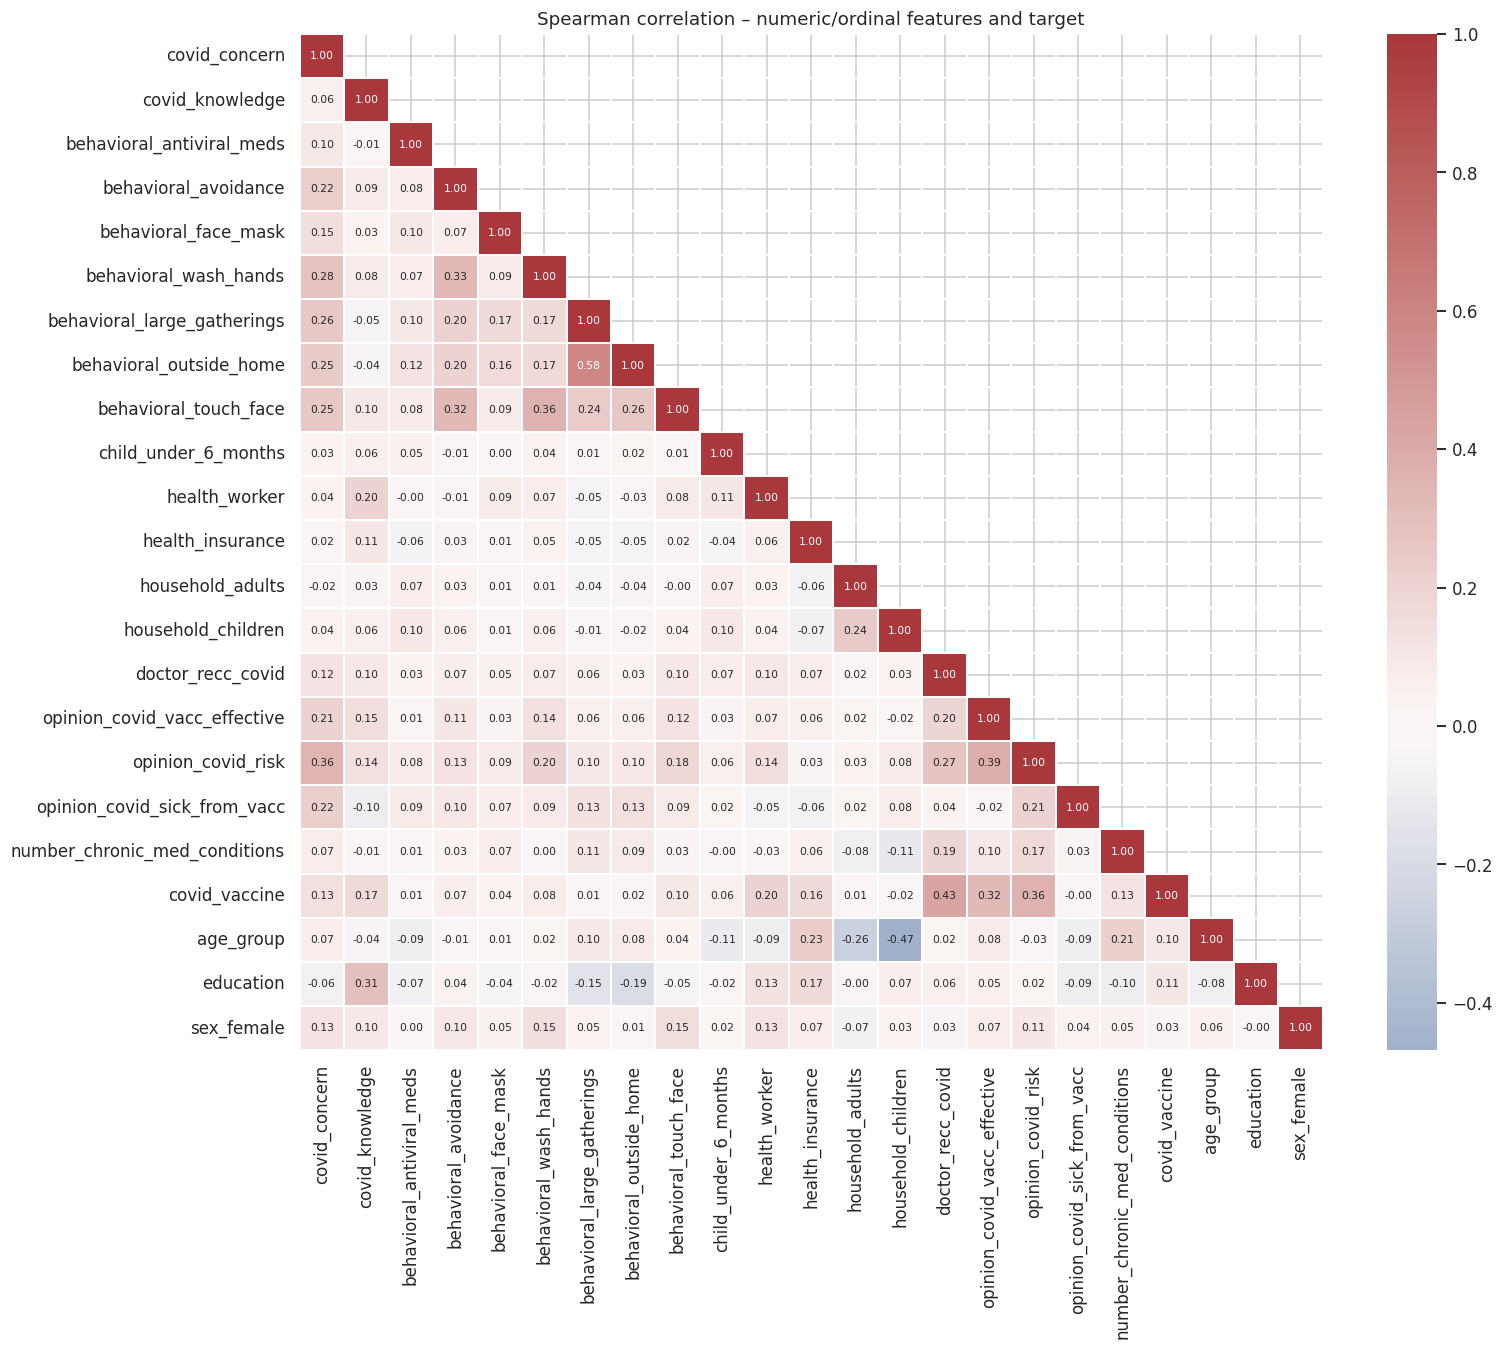

Top correlations with target:
 doctor_recc_covid                0.430
opinion_covid_risk               0.365
opinion_covid_vacc_effective     0.321
health_worker                    0.197
covid_knowledge                  0.168
health_insurance                 0.165
covid_concern                    0.134
number_chronic_med_conditions    0.126
education                        0.108
age_group                        0.099

Most collinear predictor pairs:


,a,b,rho
275,NaN,NaN,NaN
0,NaN,NaN,NaN
252,NaN,NaN,NaN
27,NaN,NaN,NaN
230,NaN,NaN,NaN
20,NaN,NaN,NaN


In [13]:
# Correlation matrix of ordinal/binary variables + target (Spearman, pairwise complete)
ordinal_map = {"age_group": ["18 - 34 Years","35 - 44 Years","45 - 54 Years","55 - 64 Years","65+ Years"],
               "education": ["< 12 Years","12 Years","Some College","College Graduate"]}
Z = train[NUM_COLS + [TARGET]].copy()
for c, order in ordinal_map.items(): Z[c] = train[c].map({v: i for i, v in enumerate(order)})
Z["sex_female"] = (train["sex"] == "Female").astype(float)
corr = Z.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), 1)
plt.figure(figsize=(15, 12)); sns.heatmap(corr, mask=mask, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.3)
plt.title("Spearman correlation – numeric/ordinal features and target"); plt.show()
print("Top correlations with target:\n", corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(10).round(3).to_string())

# Redundant feature pairs (multicollinearity check)
pairs = corr.where(~mask).stack().reset_index(); pairs.columns = ["a", "b", "rho"]
print("\nMost collinear predictor pairs:"); display(pairs[(pairs.a != TARGET) & (pairs.b != TARGET) & (pairs.a != pairs.b)].reindex(pairs.rho.abs().sort_values(ascending=False).index).head(6).round(3))

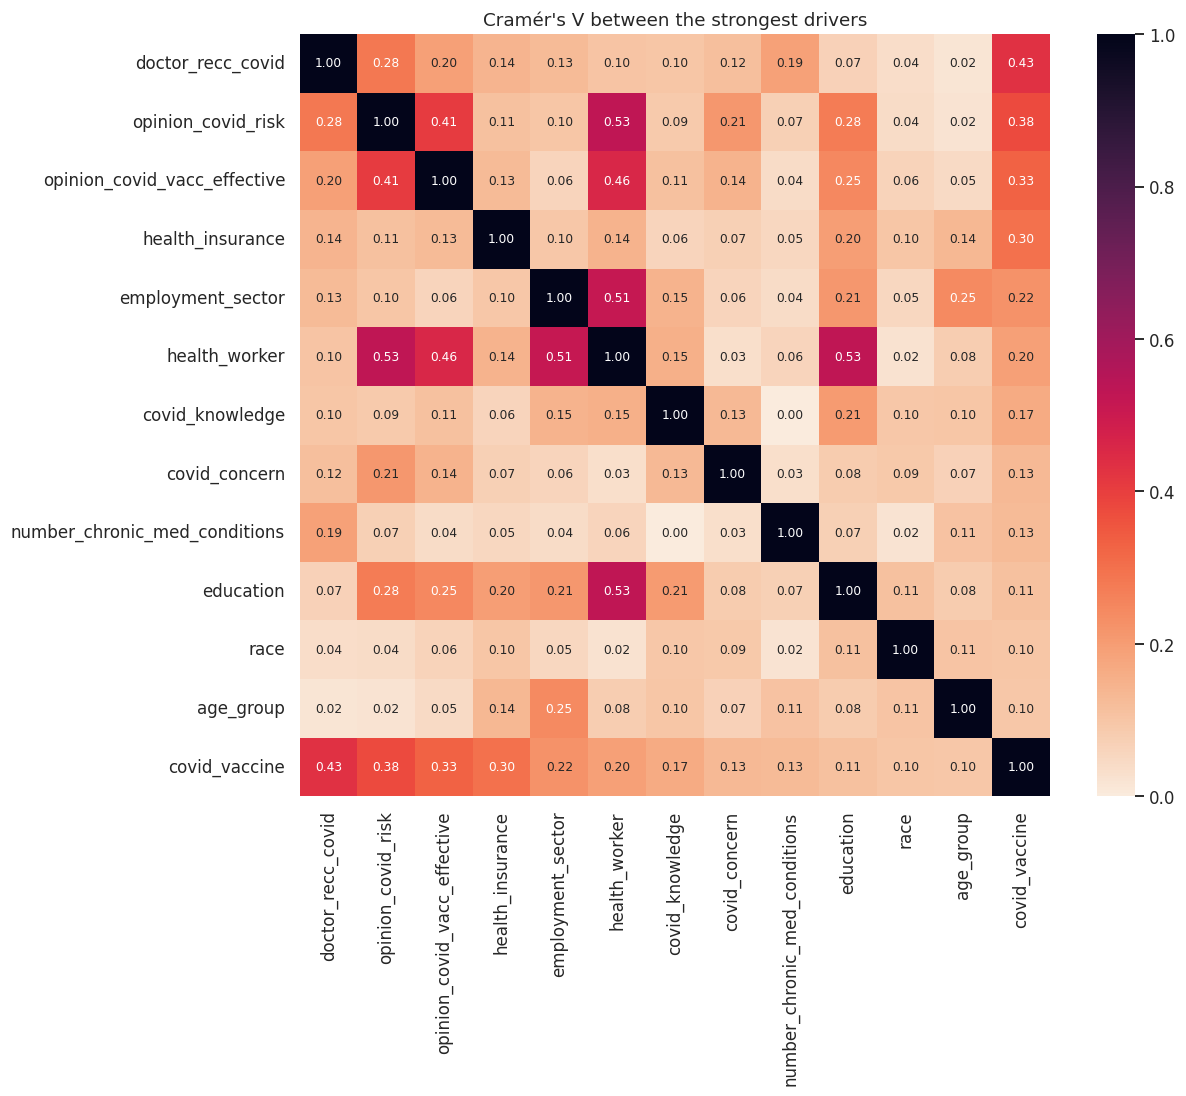

In [14]:
# Categorical x categorical: Cramér's V heat-map of the top drivers (reveals overlapping information)
top = list(assoc.index[:12]) + [TARGET]
V = pd.DataFrame(index=top, columns=top, dtype=float)
D = train[top].astype(object).where(train[top].notna(), "Missing")
for a in top:
    for b in top: V.loc[a, b] = 1.0 if a == b else cramers_v(D[a], D[b])
plt.figure(figsize=(11, 9)); sns.heatmap(V, annot=True, fmt=".2f", cmap="rocket_r", annot_kws={"size": 8}); plt.title("Cramér's V between the strongest drivers"); plt.show()

### 2.6 Deep dives into the strongest drivers and their interactions

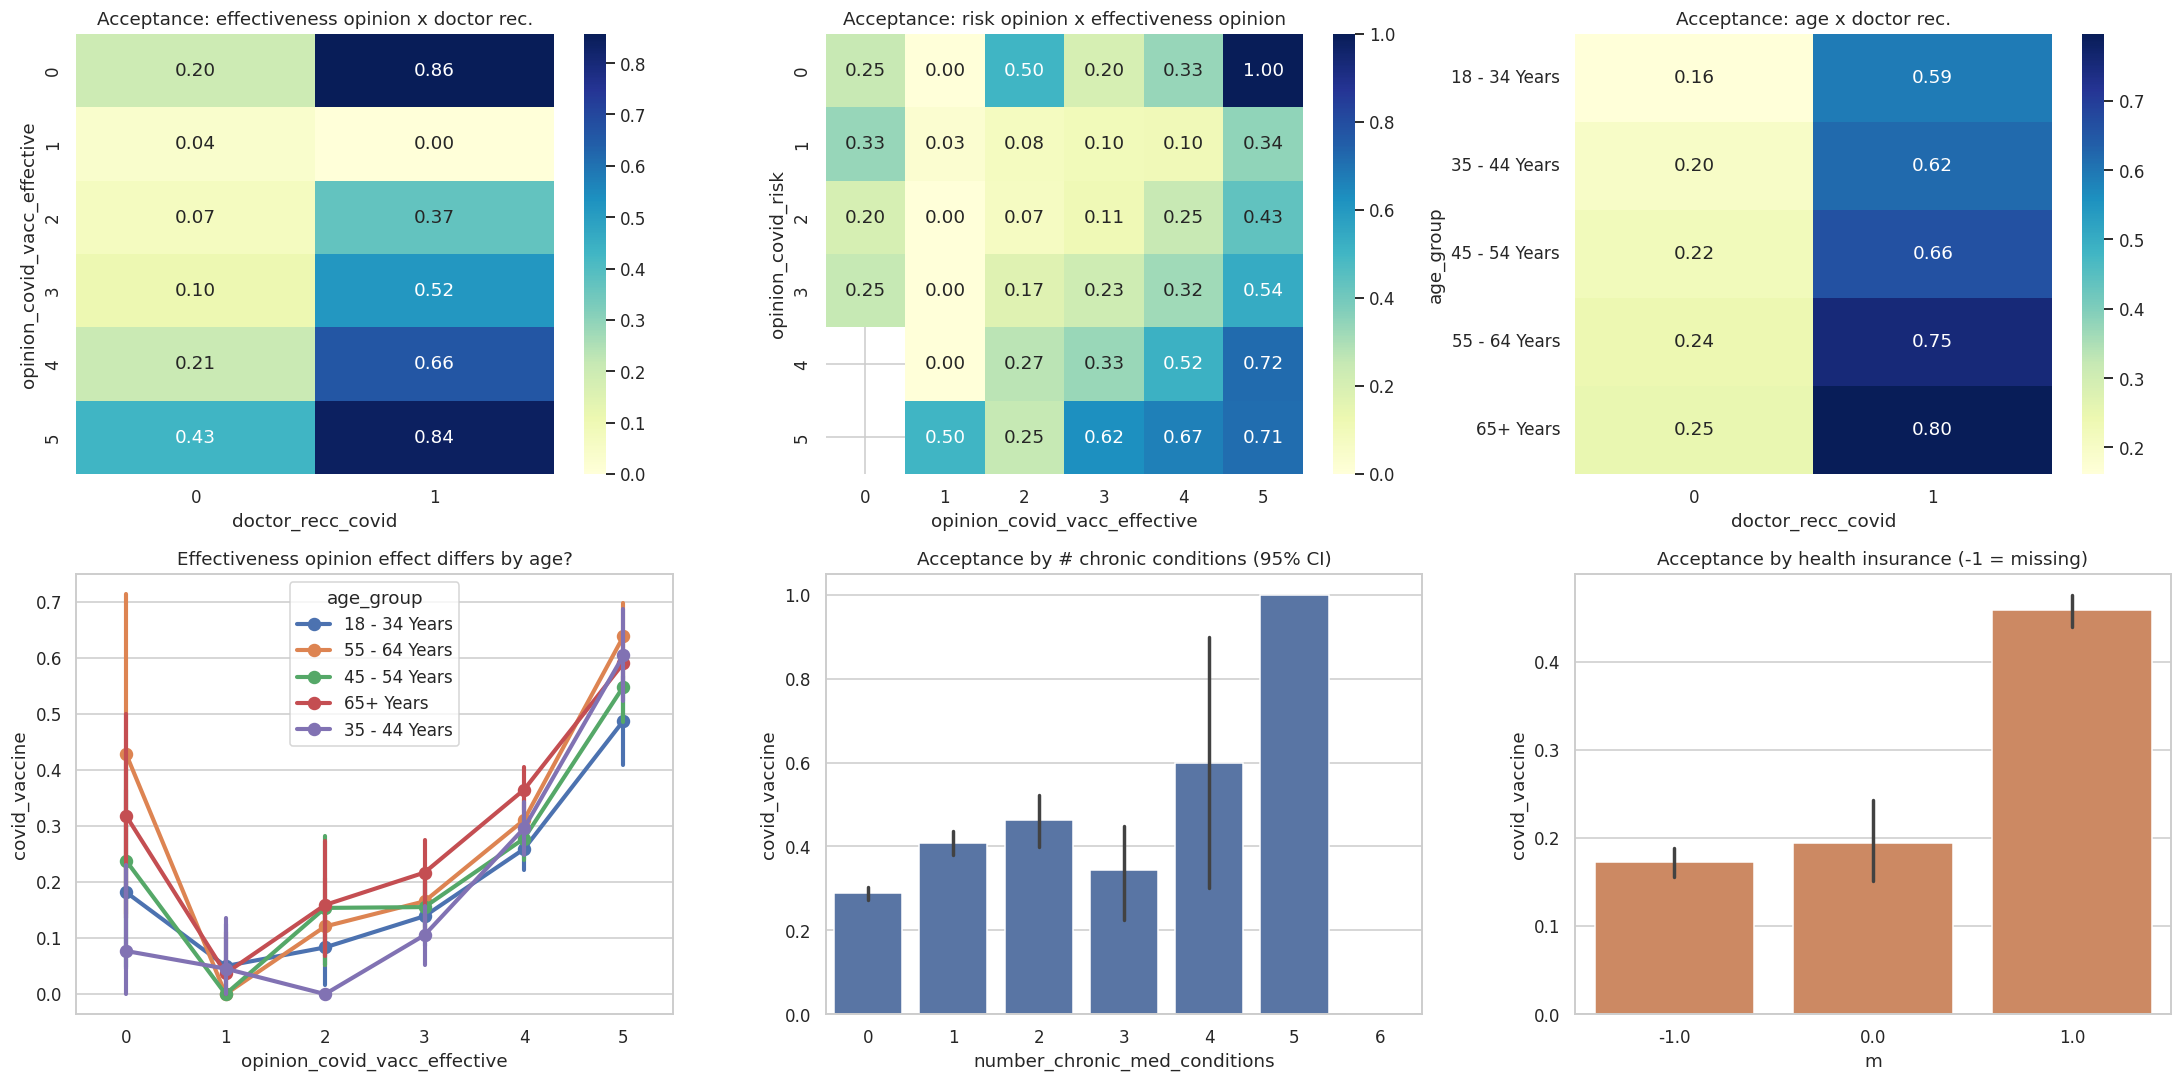

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
sns.heatmap(train.pivot_table(index="opinion_covid_vacc_effective", columns="doctor_recc_covid", values=TARGET), annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0,0]); axes[0,0].set_title("Acceptance: effectiveness opinion x doctor rec.")
sns.heatmap(train.pivot_table(index="opinion_covid_risk", columns="opinion_covid_vacc_effective", values=TARGET), annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0,1]); axes[0,1].set_title("Acceptance: risk opinion x effectiveness opinion")
sns.heatmap(train.pivot_table(index="age_group", columns="doctor_recc_covid", values=TARGET), annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0,2]); axes[0,2].set_title("Acceptance: age x doctor rec.")
sns.pointplot(data=train, x="opinion_covid_vacc_effective", y=TARGET, hue="age_group", ax=axes[1,0], errorbar=("ci", 95)); axes[1,0].set_title("Effectiveness opinion effect differs by age?")
sns.barplot(data=train, x="number_chronic_med_conditions", y=TARGET, ax=axes[1,1], color="#4c72b0"); axes[1,1].set_title("Acceptance by # chronic conditions (95% CI)")
sns.barplot(data=train.assign(m=train.health_insurance.fillna(-1)), x="m", y=TARGET, ax=axes[1,2], color="#dd8452"); axes[1,2].set_title("Acceptance by health insurance (-1 = missing)")
plt.tight_layout(); plt.show()

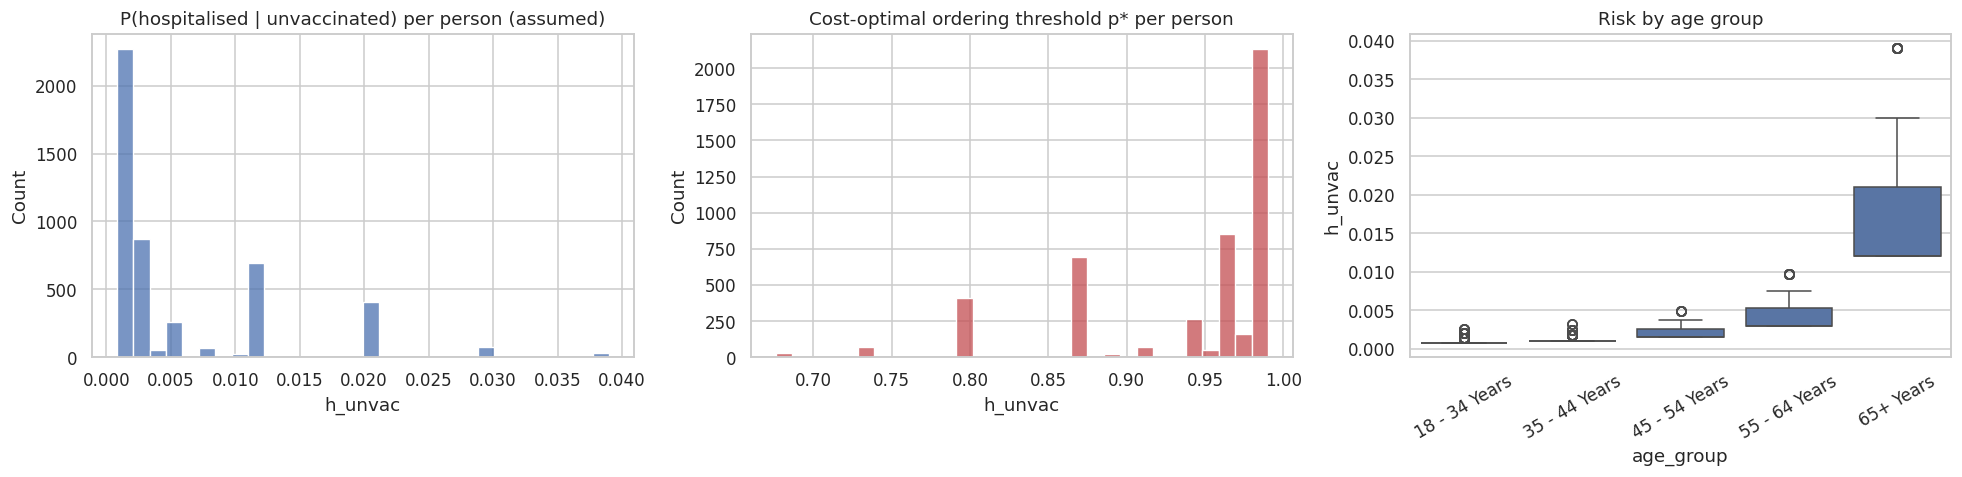

In [16]:
# How risky is each person (drives the cost threshold) and how does it relate to acceptance?
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(train["h_unvac"], bins=30, ax=ax[0]); ax[0].set_title("P(hospitalised | unvaccinated) per person (assumed)")
sns.histplot(optimal_threshold(train["h_unvac"]), bins=30, ax=ax[1], color="#c44e52"); ax[1].set_title("Cost-optimal ordering threshold p* per person")
sns.boxplot(data=train, x="age_group", y="h_unvac", order=H_UNVAC_BY_AGE.keys(), ax=ax[2]); ax[2].tick_params(axis="x", rotation=30); ax[2].set_title("Risk by age group")
plt.tight_layout(); plt.show()

In [17]:
# Shared helpers (ordinal orders, behavioural feature engineering) – defined here because EDA 2.7 and section 3 both use them
ORD = {"age_group": ["18 - 34 Years","35 - 44 Years","45 - 54 Years","55 - 64 Years","65+ Years"],
       "education": ["< 12 Years","12 Years","Some College","College Graduate"],
       "income_poverty": ["Below Poverty","<= $75,000, Above Poverty","> $75,000"]}
BEH = [c for c in NUM_COLS if c.startswith("behavioral_")]
MISS_IND = ["health_insurance", "employment_sector", "income_poverty", "education", "rent_or_own", "employment_status"]

def engineer(df):
    '''Domain features (row-wise, no target information -> safe inside CV).'''
    d = df.copy()
    d["n_protective"] = d[["behavioral_avoidance","behavioral_face_mask","behavioral_wash_hands","behavioral_large_gatherings","behavioral_outside_home"]].sum(axis=1)
    d["opinion_balance"] = d["opinion_covid_vacc_effective"] - d["opinion_covid_sick_from_vacc"]       # effective minus side-effect fear
    d["risk_x_effective"] = d["opinion_covid_risk"] * d["opinion_covid_vacc_effective"]
    d["age_ord"] = d["age_group"].map({v: i for i, v in enumerate(ORD["age_group"])})
    d["age_x_doctor"] = d["age_ord"] * (1 + d["doctor_recc_covid"])
    d["n_missing"] = d[FEATURES].isna().sum(axis=1)
    # --- behavioural trait composites (domain knowledge of how COVID spreads / is reduced) ---
    d["hygiene_score"]   = d[["behavioral_face_mask","behavioral_wash_hands","behavioral_touch_face"]].sum(axis=1)       # barrier + hygiene
    d["distancing_score"] = d[["behavioral_avoidance","behavioral_large_gatherings","behavioral_outside_home"]].sum(axis=1) # reduced contact
    d["protection_rr"]   = np.prod([np.where(d[c] == 1, rr, 1.0) for c, rr in BEH_RR.items()], axis=0)                   # combined relative-risk multiplier
    d["exposed_unprotected"] = (((d["health_worker"] == 1) | (d["child_under_6_months"] == 1)) & (d["n_protective"] <= 1)).astype(int)
    d["behav_x_risk"]    = d["n_protective"] * d["opinion_covid_risk"]          # precaution-takers who also believe risk is high
    d["distancing_x_age"] = d["distancing_score"] * d["age_ord"]
    return d

def add_missing_flags(df):
    d = df.copy()
    for c in MISS_IND: d[c + "_NA"] = d[c].isna().astype(int)
    return d

### 2.7 Behavioural traits – new correlation analysis
**Domain reasoning.** COVID spreads through respiratory droplets/aerosols at close, crowded, indoor gatherings (winter parties). Masks and hand hygiene reduce viral dose and transmission; avoiding contact and crowds reduces exposure; antivirals soften disease. In this task everyone is infected, so the behaviours matter in two ways: (i) as **predictors of vaccine acceptance** (people who take precautions are more health-conscious / risk-aware) and (ii) as **modifiers of hospitalisation risk** (cost side, see `BEH_RR`). Below we test (i) from the data and build composite behavioural features.

,prevalence,accept_if_yes,accept_if_no,phi_with_target,p_value
behaviour,,,,,
behavioral_touch_face,0.694,0.357,0.258,0.097,0.000
behavioral_wash_hands,0.839,0.343,0.246,0.075,0.000
behavioral_avoidance,0.733,0.346,0.274,0.068,0.000
behavioral_face_mask,0.073,0.389,0.322,0.037,0.012
behavioral_outside_home,0.329,0.338,0.322,0.017,0.265
behavioral_antiviral_meds,0.053,0.348,0.325,0.011,0.499
behavioral_large_gatherings,0.356,0.332,0.324,0.009,0.566


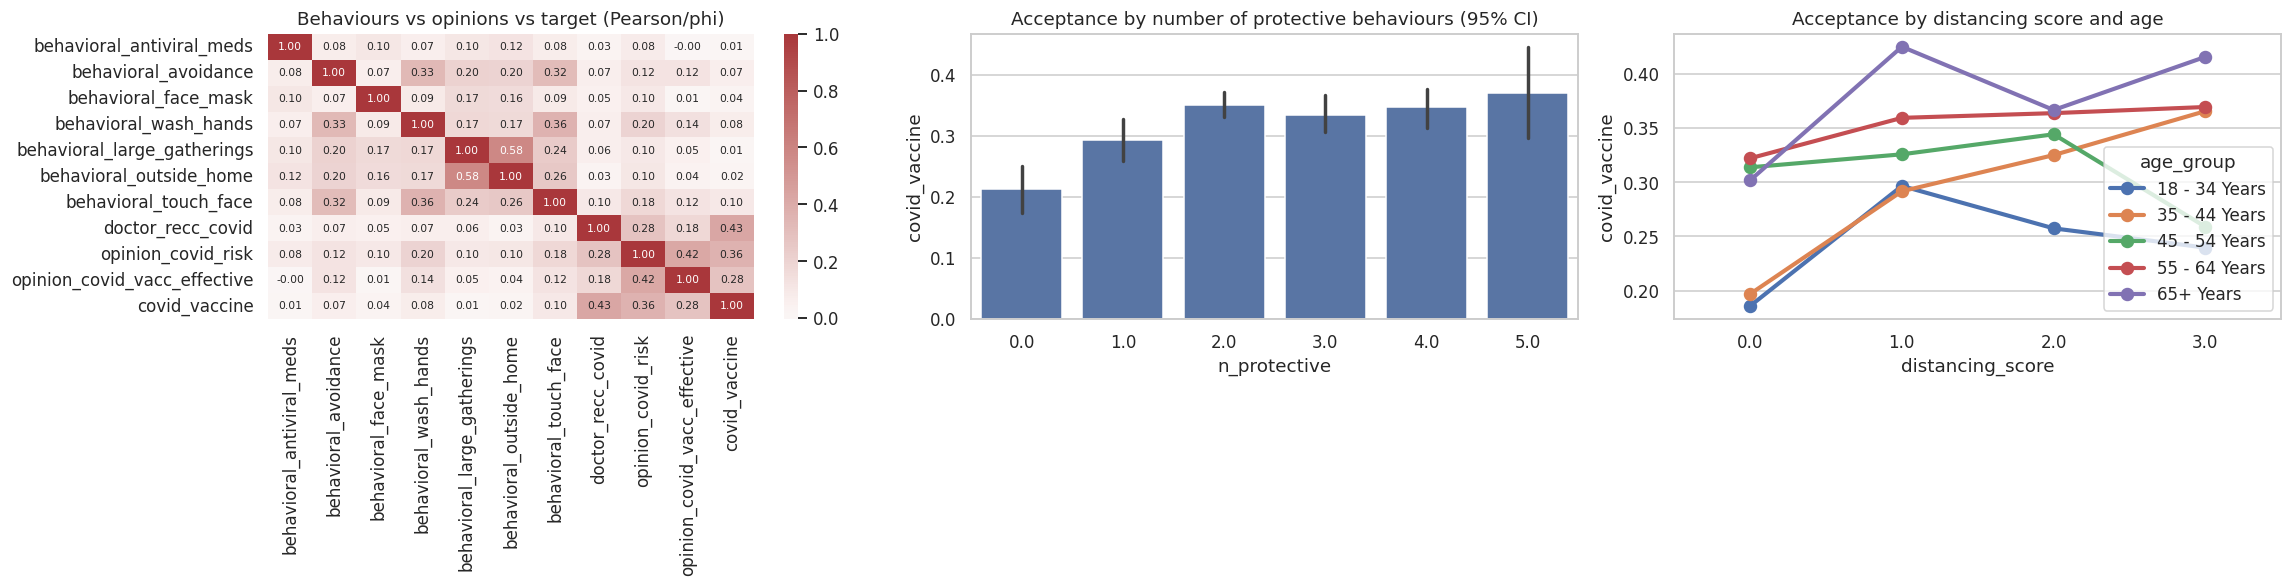

Correlation of composites with target:
n_protective           0.060
hygiene_score          0.104
distancing_score       0.043
protection_rr            NaN
behav_x_risk           0.260
exposed_unprotected    0.052


In [18]:
BEH_ALL = [c for c in FEATURES if c.startswith("behavioral_")]
tab = []
for c in BEH_ALL:
    g = train.groupby(c)[TARGET].mean()
    sub = train[[c, TARGET]].dropna()
    phi = np.corrcoef(sub[c], sub[TARGET])[0, 1]
    p = stats.chi2_contingency(pd.crosstab(sub[c], sub[TARGET]))[1]
    tab.append(dict(behaviour=c, prevalence=train[c].mean(), accept_if_yes=g.get(1.0), accept_if_no=g.get(0.0), phi_with_target=phi, p_value=p))
beh = pd.DataFrame(tab).set_index("behaviour").sort_values("phi_with_target", ascending=False); display(beh.round(3))

# Behaviour composites and their link with target
E = engineer(train)
comp = ["n_protective", "hygiene_score", "distancing_score", "protection_rr", "behav_x_risk", "exposed_unprotected"]
fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
sns.heatmap(train[BEH_ALL + ["doctor_recc_covid", "opinion_covid_risk", "opinion_covid_vacc_effective", TARGET]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 7}, ax=ax[0]); ax[0].set_title("Behaviours vs opinions vs target (Pearson/phi)")
sns.barplot(data=E, x="n_protective", y=TARGET, ax=ax[1], color="#4c72b0"); ax[1].set_title("Acceptance by number of protective behaviours (95% CI)")
sns.pointplot(data=E, x="distancing_score", y=TARGET, hue="age_group", hue_order=ORD["age_group"], ax=ax[2], errorbar=None); ax[2].set_title("Acceptance by distancing score and age")
plt.tight_layout(); plt.show()
print("Correlation of composites with target:"); print(E[comp + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).round(3).to_string())

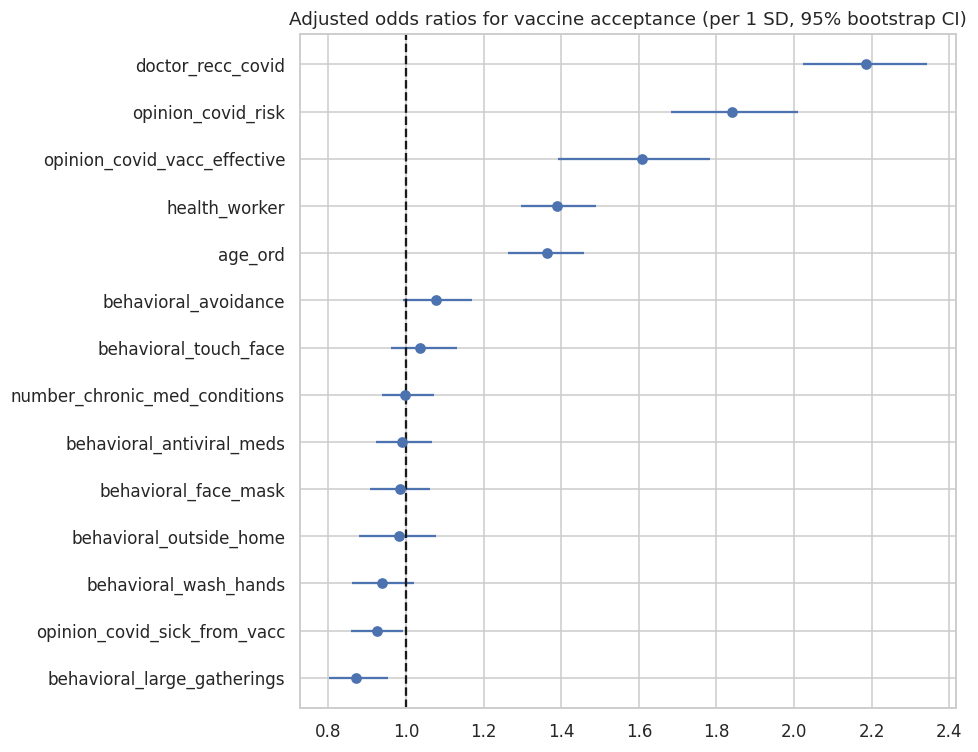

Behaviours whose CI excludes 1 (independent signal): ['behavioral_large_gatherings']


In [19]:
# Is the behaviour effect INDEPENDENT of doctor recommendation, opinions and age? -> adjusted odds ratios (logistic regression + bootstrap CI)
adj_cols = BEH_ALL + ["doctor_recc_covid", "opinion_covid_risk", "opinion_covid_vacc_effective", "opinion_covid_sick_from_vacc", "health_worker", "number_chronic_med_conditions"]
A = train[adj_cols].fillna(train[adj_cols].median()).copy(); A["age_ord"] = E["age_ord"].values
A = (A - A.mean()) / A.std()
yv = train[TARGET].to_numpy(); rng = np.random.default_rng(SEED); coefs = []
for _ in range(200):
    ix = rng.integers(0, len(A), len(A)); coefs.append(LogisticRegression(C=1.0, max_iter=500).fit(A.iloc[ix], yv[ix]).coef_[0])
coefs = np.array(coefs); orr = pd.DataFrame({"odds_ratio_per_SD": np.exp(coefs.mean(0)), "ci_low": np.exp(np.percentile(coefs, 2.5, 0)), "ci_high": np.exp(np.percentile(coefs, 97.5, 0))}, index=A.columns).sort_values("odds_ratio_per_SD")
plt.figure(figsize=(9, 7)); plt.errorbar(orr.odds_ratio_per_SD, range(len(orr)), xerr=[orr.odds_ratio_per_SD - orr.ci_low, orr.ci_high - orr.odds_ratio_per_SD], fmt="o", c="#4c72b0")
plt.yticks(range(len(orr)), orr.index); plt.axvline(1, c="k", ls="--"); plt.title("Adjusted odds ratios for vaccine acceptance (per 1 SD, 95% bootstrap CI)"); plt.tight_layout(); plt.show()
print("Behaviours whose CI excludes 1 (independent signal):", [i for i in orr.index if i.startswith("behavioral_") and (orr.loc[i, "ci_low"] > 1 or orr.loc[i, "ci_high"] < 1)])

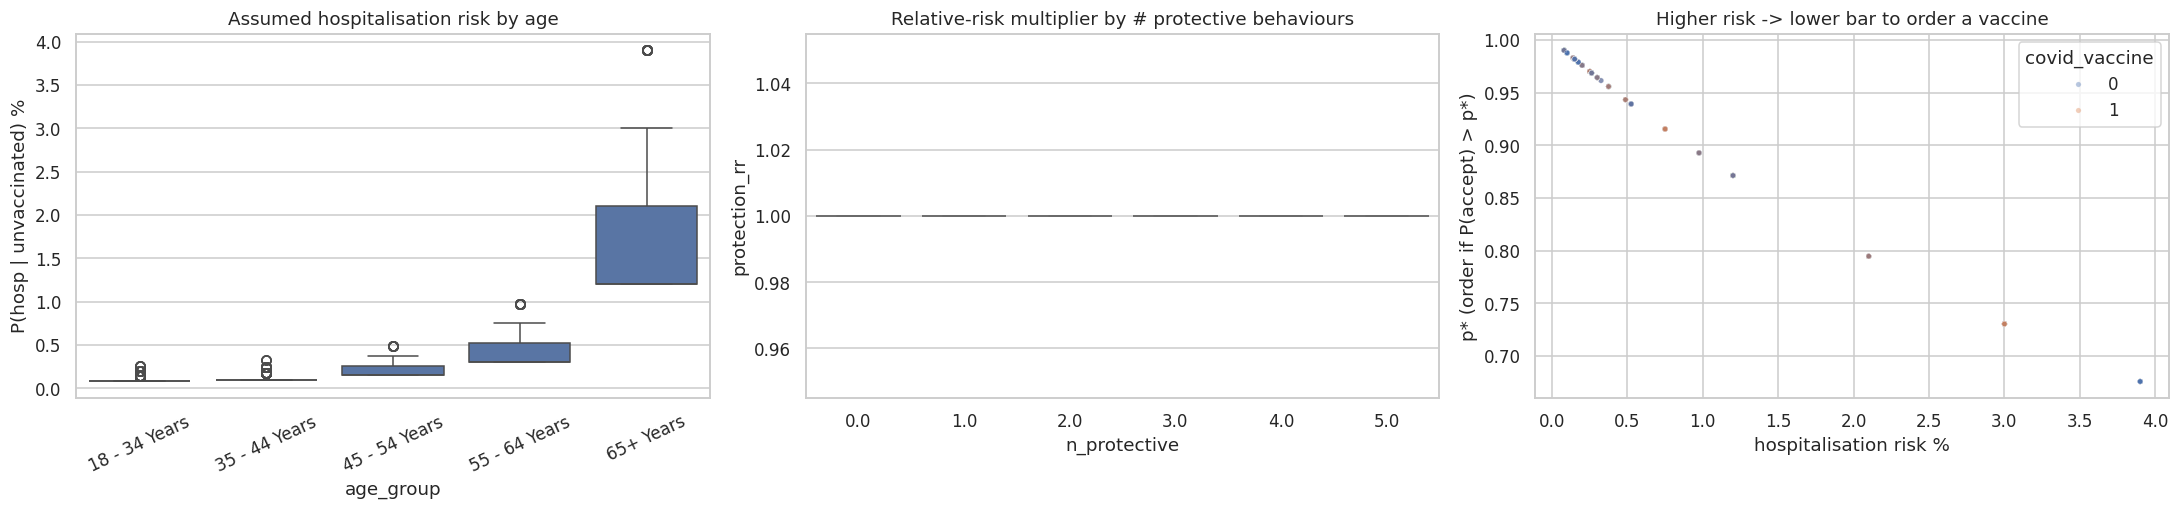

In [20]:
# Cost-side view: how the behavioural risk multiplier changes the per-person hospitalisation risk and the ordering threshold
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
sns.boxplot(data=train.assign(h=train["h_unvac"]*100), x="age_group", y="h", order=list(H_UNVAC_BY_AGE), ax=ax[0]); ax[0].set_ylabel("P(hosp | unvaccinated) %"); ax[0].tick_params(axis="x", rotation=25); ax[0].set_title("Assumed hospitalisation risk by age")
sns.boxplot(x=E["n_protective"], y=E["protection_rr"], ax=ax[1], color="#8fbcd4"); ax[1].set_title("Relative-risk multiplier by # protective behaviours")
sns.scatterplot(x=train["h_unvac"]*100, y=optimal_threshold(train["h_unvac"]), hue=train[TARGET], alpha=.4, ax=ax[2], s=12); ax[2].set_xlabel("hospitalisation risk %"); ax[2].set_ylabel("p* (order if P(accept) > p*)"); ax[2].set_title("Higher risk -> lower bar to order a vaccine")
plt.tight_layout(); plt.show()

**EDA take-aways (drive the modelling decisions)**
* Target is imbalanced (~33 % accept) → use probability models + cost-based threshold rather than accuracy; stratified CV.
* Strongest, consistent drivers: doctor recommendation, opinion of effectiveness, opinion of risk, age, health-insurance, plus behavioural variables (mask, avoidance). Relationship is mostly monotonic on the ordinal scales → linear models are a strong baseline; interactions (age x opinion) → boosted trees may add a bit.
* `health_insurance` (~40 %) and `employment_sector` (~49 %) have heavy missingness that is itself informative → missing-indicator / "Missing" category rather than dropping.
* Low adversarial AUC → test set comes from the same distribution; CV estimates should transfer.
* Behavioural traits (masks, hygiene, avoiding crowds) correlate positively with acceptance but much of that signal overlaps with doctor recommendation and risk/effectiveness opinions (section 2.7); they still add independent information and are summarised in composite features.
* Several behavioural flags are mutually correlated → regularisation / ensembling helps.

## 3. Pre-processing options
Three pipelines are compared using the *same* two probe models (logistic regression + gradient boosting) so differences are due to pre-processing only:

| Variant | Encoding | Missing values | Extra features |
|---|---|---|---|
| **A – baseline** | one-hot for all text columns, scaling | median / "Missing" | – |
| **B – ordinal + indicators** | ordinal codes for age/education/income (order is meaningful), one-hot for nominal | median + binary missing-indicators | – |
| **C – B + engineered** | as B | as B | behavioural composites (hygiene, distancing, protective count, combined risk multiplier, exposed-but-unprotected), opinion contrasts, age x doctor-rec, behaviour x risk-opinion |

In [21]:
def make_preprocessor(variant, scale=True):
    '''Returns an (unfitted) sklearn transformer for the chosen pre-processing variant.'''
    sc = [("scaler", StandardScaler())] if scale else []
    if variant == "A":
        nums = NUM_COLS; cats = CAT_COLS; ords = []; pre = None
    else:
        ords = list(ORD); cats = [c for c in CAT_COLS if c not in ORD]
        nums = NUM_COLS + [c + "_NA" for c in MISS_IND]
        if variant == "C": nums = nums + ["n_protective","opinion_balance","risk_x_effective","age_x_doctor","n_missing","hygiene_score","distancing_score","protection_rr","exposed_unprotected","behav_x_risk","distancing_x_age"]
    ct = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median"))] + sc), nums),
        ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OrdinalEncoder(categories=[ORD[c] for c in ords], handle_unknown="use_encoded_value", unknown_value=-1))] + sc), ords) if ords else ("drop_ord", "drop", []),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=20))]), cats),
    ])
    steps = []
    if variant == "C": steps.append(("eng", FunctionTransformer(engineer)))
    if variant != "A": steps.append(("flags", FunctionTransformer(add_missing_flags)))
    return Pipeline(steps + [("ct", ct)])

X, y, h = train[FEATURES], train[TARGET].to_numpy(), train["h_unvac"].to_numpy()
X_test, h_test = test[FEATURES], test["h_unvac"].to_numpy()
# Unseen hold-out (never used for tuning/ranking decisions) + development set
idx_dev, idx_hold = train_test_split(np.arange(len(train)), test_size=0.2, stratify=y, random_state=SEED)
X_dev, y_dev, h_dev = X.iloc[idx_dev], y[idx_dev], h[idx_dev]
X_hold, y_hold, h_hold = X.iloc[idx_hold], y[idx_hold], h[idx_hold]
print("dev:", X_dev.shape, "hold-out:", X_hold.shape)

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)   # 10 folds -> estimates variance
def cv_oof_metrics(pipe, Xd=X_dev, yd=y_dev, hd=h_dev):
    '''Repeated 5-fold CV. Returns per-fold dict list (AUC, logloss, Brier, cost/person with p*-rule).'''
    out = []
    for tr, va in CV.split(Xd, yd):
        m = clone(pipe).fit(Xd.iloc[tr], yd[tr]); p = m.predict_proba(Xd.iloc[va])[:, 1]
        out.append(dict(auc=roc_auc_score(yd[va], p), logloss=log_loss(yd[va], p), brier=brier_score_loss(yd[va], p),
                        cost=total_cost(yd[va], decide(p, hd[va]), hd[va]) / len(va),
                        cost_t50=total_cost(yd[va], (p > .5).astype(int), hd[va]) / len(va)))
    return pd.DataFrame(out)

probe = {"LogReg": LogisticRegression(C=0.1, max_iter=2000),
         "HistGB":  HistGradientBoostingClassifier(learning_rate=0.05, max_iter=150, max_depth=3, random_state=SEED)}
rows = []
for v in ["A", "B", "C"]:
    for name, clf in probe.items():
        r = cv_oof_metrics(Pipeline([("pre", make_preprocessor(v, scale=name == "LogReg")), ("clf", clf)]))
        rows.append(dict(variant=v, model=name, **r.mean().add_suffix("_mean").to_dict(), cost_sd=r.cost.std()))
pp = pd.DataFrame(rows); display(pp.round(4))

dev: (3804, 29) hold-out: (952, 29)


,variant,model,auc_mean,logloss_mean,brier_mean,cost_mean,cost_t50_mean,cost_sd
0,A,LogReg,0.8276,0.4684,0.1489,721.2096,795.0346,6.6311
1,A,HistGB,0.8395,0.4555,0.1460,722.1746,792.8572,7.2347
2,B,LogReg,0.8565,0.4328,0.1349,718.4582,788.0813,5.3410
3,B,HistGB,0.8635,0.4223,0.1334,718.1830,792.6980,4.9938
4,C,LogReg,0.8585,0.4282,0.1341,719.4680,782.7261,6.5307
5,C,HistGB,0.8626,0.4229,0.1335,718.4517,792.1997,6.5688


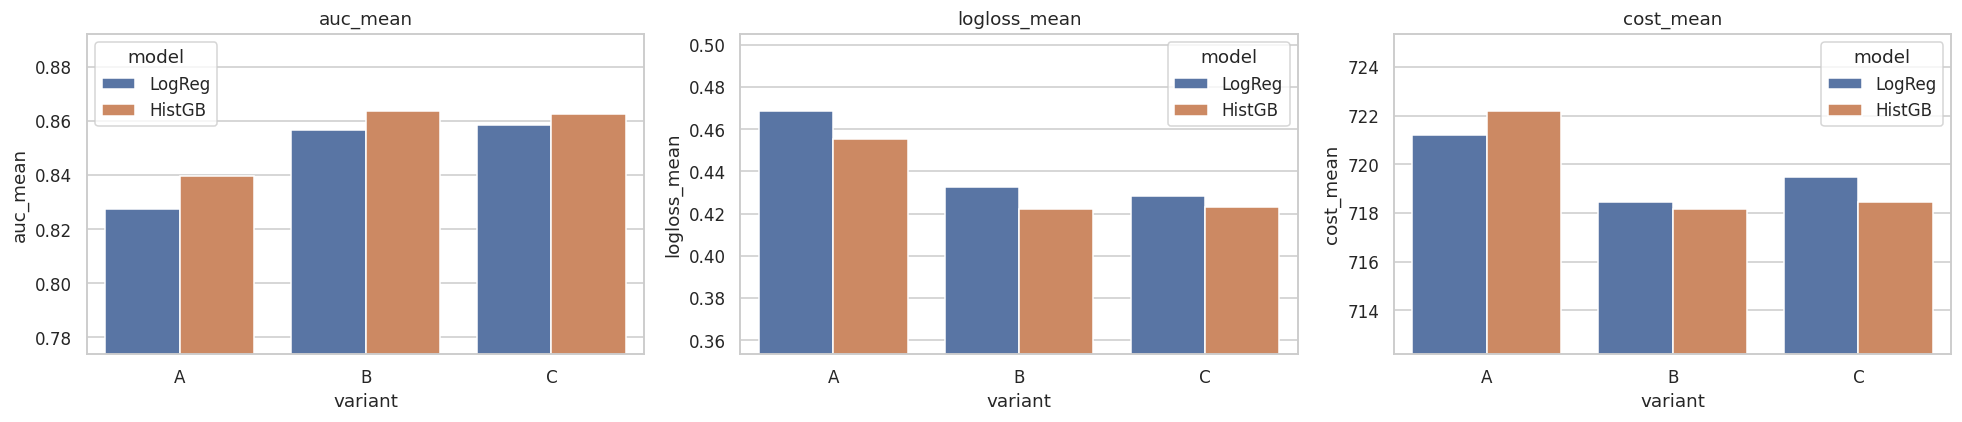

Best pre-processing variant by mean cost: B | by logloss: C


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, m in zip(ax, ["auc_mean", "logloss_mean", "cost_mean"]):
    sns.barplot(data=pp, x="variant", y=m, hue="model", ax=a); a.set_title(m)
    lo, hi = pp[m].min(), pp[m].max(); a.set_ylim(lo - (hi-lo)*1.5, hi + (hi-lo)*.8)
plt.tight_layout(); plt.show()
best_variant = pp.groupby("variant")["cost_mean"].mean().idxmin()
print("Best pre-processing variant by mean cost:", best_variant, "| by logloss:", pp.groupby("variant")["logloss_mean"].mean().idxmin())

The variant with the lowest cost (ties broken by log-loss, i.e. probability quality, which is what the decision rule consumes) is used for all following models. Differences are small relative to fold-to-fold noise, which is itself an informative result: the signal sits in a handful of strong features and the data are fairly clean after imputation.

## 4. Models and hyper-parameter tuning
Five model families with different inductive biases: regularised **logistic regression** (linear, calibrated), **random forest** & **extra trees** (bagged trees), **gradient boosting** (sklearn GB) and **histogram gradient boosting**. Hyper-parameters are tuned by randomised search with **inner 3-fold CV on the development set only**, scoring **log-loss** (proper scoring rule → good probabilities → good cost decisions). Then each tuned model is evaluated with repeated CV on the cost metric.

In [23]:
from scipy.stats import loguniform, randint, uniform
PRE = best_variant
def pipe(clf, scale=False): return Pipeline([("pre", make_preprocessor(PRE, scale=scale)), ("clf", clf)])

search_space = {
 "LogReg": (pipe(LogisticRegression(max_iter=3000), True),
            {"clf__C": loguniform(1e-3, 10), "clf__penalty": ["l2"], "clf__class_weight": [None]}),
 "RandomForest": (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
            {"clf__max_depth": randint(3, 14), "clf__min_samples_leaf": randint(5, 60), "clf__max_features": uniform(0.15, 0.6)}),
 "ExtraTrees": (pipe(ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
            {"clf__max_depth": randint(3, 16), "clf__min_samples_leaf": randint(5, 60), "clf__max_features": uniform(0.15, 0.6)}),
 "GradBoost": (pipe(GradientBoostingClassifier(random_state=SEED)),
            {"clf__n_estimators": randint(60, 300), "clf__learning_rate": loguniform(0.01, 0.15), "clf__max_depth": randint(2, 5),
             "clf__subsample": uniform(0.6, 0.4), "clf__min_samples_leaf": randint(10, 80)}),
 "HistGB": (pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False)),
            {"clf__max_iter": randint(60, 300), "clf__learning_rate": loguniform(0.01, 0.15), "clf__max_depth": randint(2, 5),
             "clf__min_samples_leaf": randint(20, 120), "clf__l2_regularization": loguniform(1e-2, 20)}),
}
tuned, tuning_log = {}, []
for name, (p, space) in search_space.items():
    t0 = time.time()
    rs = RandomizedSearchCV(p, space, n_iter=25 if name != "LogReg" else 12, scoring="neg_log_loss",
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=-1)
    rs.fit(X_dev, y_dev); tuned[name] = rs.best_estimator_
    tuning_log.append(dict(model=name, best_inner_logloss=-rs.best_score_, secs=round(time.time()-t0), **{k.split('__')[1]: round(v, 4) if isinstance(v, float) else v for k, v in rs.best_params_.items()}))
display(pd.DataFrame(tuning_log).set_index("model"))

,best_inner_logloss,secs,C,class_weight,penalty,max_depth,max_features,min_samples_leaf,learning_rate,n_estimators,subsample,l2_regularization,max_iter
model,,,,,,,,,,,,,
LogReg,0.429621,10,2.9154,NaN,l2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RandomForest,0.436597,112,NaN,NaN,NaN,8.0,0.2748,8.0,NaN,NaN,NaN,NaN,NaN
ExtraTrees,0.436941,120,NaN,NaN,NaN,12.0,0.4199,14.0,NaN,NaN,NaN,NaN,NaN
GradBoost,0.420978,89,NaN,NaN,NaN,2.0,NaN,12.0,0.0403,288.0,0.843,NaN,NaN
HistGB,0.428436,30,NaN,NaN,NaN,3.0,NaN,46.0,0.0785,NaN,NaN,2.2617,201.0


In [24]:
# Soft-voting ensembles of the tuned models + isotonic/sigmoid calibration of the strongest single model
from sklearn.ensemble import VotingClassifier
tuned["Ensemble_all"]  = Pipeline([("vote", VotingClassifier([(n, tuned[n]) for n in ["LogReg","RandomForest","ExtraTrees","GradBoost","HistGB"]], voting="soft"))])
tuned["Ensemble_LR+GB"] = Pipeline([("vote", VotingClassifier([(n, tuned[n]) for n in ["LogReg","GradBoost","HistGB"]], voting="soft"))])
tuned["LogReg_calibrated"] = Pipeline([("cal", CalibratedClassifierCV(tuned["LogReg"], method="isotonic", cv=5))])
tuned["HistGB_calibrated"] = Pipeline([("cal", CalibratedClassifierCV(tuned["HistGB"], method="sigmoid", cv=5))])
print(list(tuned))

['LogReg', 'RandomForest', 'ExtraTrees', 'GradBoost', 'HistGB', 'Ensemble_all', 'Ensemble_LR+GB', 'LogReg_calibrated', 'HistGB_calibrated']


## 5. Performance analysis
Each candidate is scored on the development set with **10 folds (5-fold x 2 repeats)**: mean and standard deviation of cost per person show the random variation. Then each is refit on all development data and scored on the **unseen hold-out**. Cost is computed with the decision rule *order iff p > p\**; a naïve 0.5 threshold is shown for contrast.

In [25]:
res, fold_tables = [], {}
for name, m in tuned.items():
    r = cv_oof_metrics(m); fold_tables[name] = r
    fit = clone(m).fit(X_dev, y_dev); ph = fit.predict_proba(X_hold)[:, 1]
    dh = decide(ph, h_hold)
    res.append(dict(model=name, cv_cost_mean=r.cost.mean(), cv_cost_sd=r.cost.std(), cv_cost_t50=r.cost_t50.mean(),
                    cv_auc=r.auc.mean(), cv_logloss=r.logloss.mean(), cv_brier=r.brier.mean(),
                    hold_cost=total_cost(y_hold, dh, h_hold) / len(y_hold), hold_auc=roc_auc_score(y_hold, ph),
                    hold_acc_at_rule=accuracy_score(y_hold, dh), hold_orders_pct=dh.mean()*100))
results = pd.DataFrame(res).set_index("model").sort_values("cv_cost_mean")
display(results.round(4).style.background_gradient(subset=["cv_cost_mean", "hold_cost"], cmap="Greens_r"))

bl = {"oracle": total_cost(y_hold, y_hold, h_hold), "order nobody": total_cost(y_hold, 0*y_hold, h_hold), "order everybody": total_cost(y_hold, 0*y_hold+1, h_hold)}
print("Hold-out baselines (cost/person):", {k: round(v/len(y_hold), 2) for k, v in bl.items()})

,cv_cost_mean,cv_cost_sd,cv_cost_t50,cv_auc,cv_logloss,cv_brier,hold_cost,hold_auc,hold_acc_at_rule,hold_orders_pct
model,,,,,,,,,,
HistGB,718.201100,5.783500,796.318800,0.860200,0.425700,0.134200,746.318400,0.860200,0.700600,4.621800
HistGB_calibrated,718.422800,5.425300,789.783000,0.862000,0.423100,0.133500,741.396700,0.860900,0.699600,3.676500
ExtraTrees,718.557500,5.275000,792.102800,0.857600,0.432200,0.136900,739.857400,0.861200,0.697500,3.256300
Ensemble_all,718.749200,5.332200,783.218800,0.866500,0.419500,0.132100,742.595800,0.867300,0.694300,3.151300
Ensemble_LR+GB,718.780200,5.065900,786.246400,0.866100,0.417900,0.131400,744.018800,0.867000,0.698500,3.781500
RandomForest,719.097600,5.658700,783.662900,0.860200,0.432500,0.136700,740.136400,0.859600,0.691200,2.205900
LogReg,719.748400,6.366400,792.674000,0.857700,0.432500,0.134600,741.085600,0.859300,0.700600,3.571400
GradBoost,719.975900,5.830200,785.225100,0.865600,0.419000,0.132000,743.155400,0.865400,0.698500,3.571400
LogReg_calibrated,720.323100,5.889200,784.453300,0.856500,0.440700,0.135100,741.460200,0.858300,0.714300,5.777300


Hold-out baselines (cost/person): {'oracle': np.float64(700.49), 'order nobody': np.float64(744.41), 'order everybody': np.float64(1710.46)}


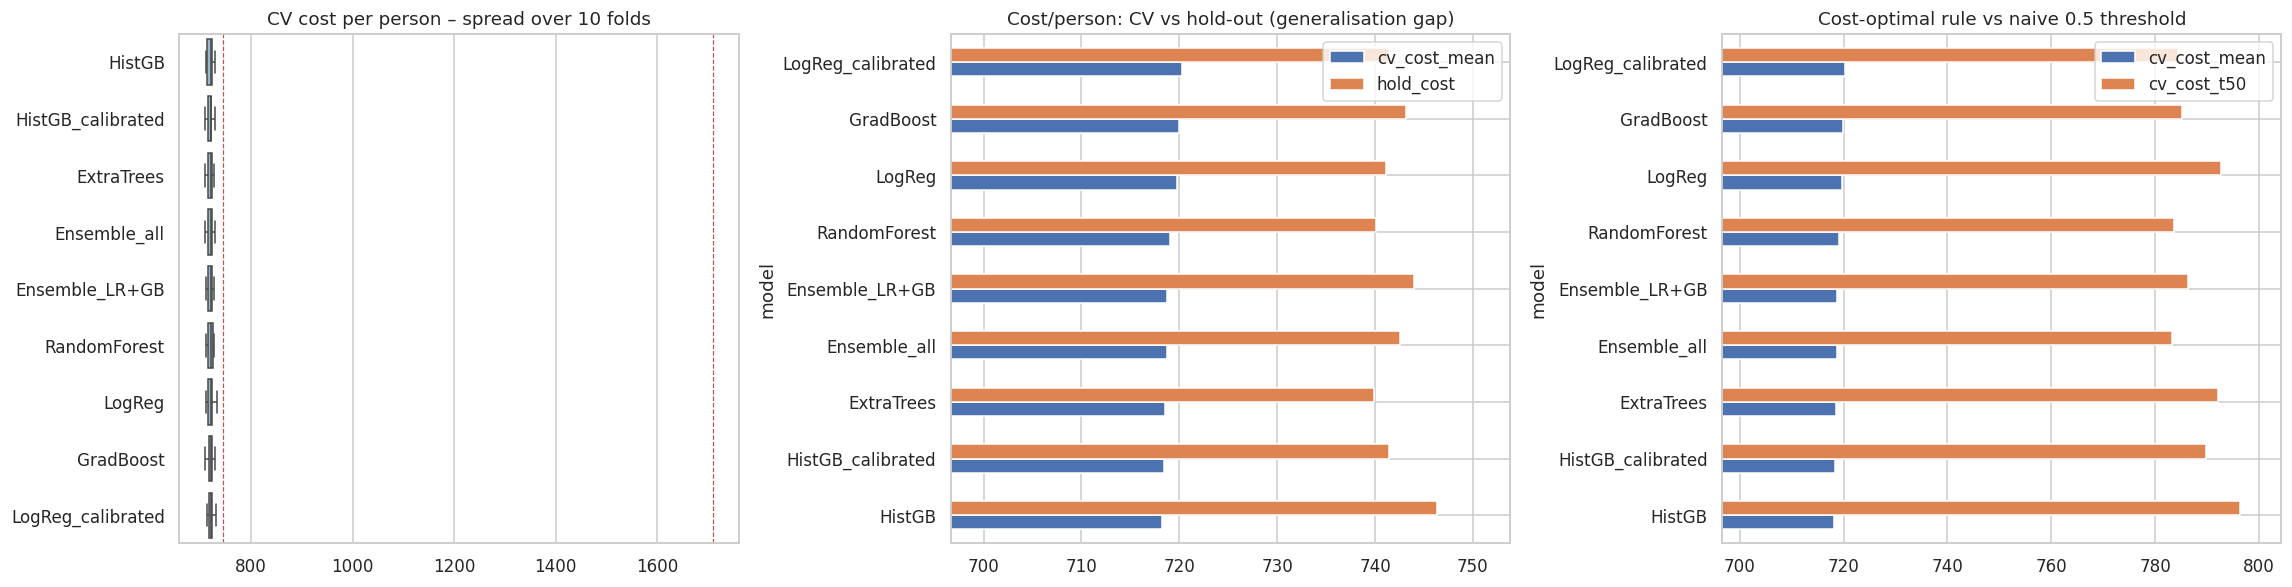

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
order = results.index
sns.boxplot(data=pd.concat({n: fold_tables[n].cost for n in order}, axis=1), orient="h", ax=ax[0], color="#8fbcd4"); ax[0].set_title("CV cost per person – spread over 10 folds")
for lbl, v in {"order nobody": bl["order nobody"], "order everybody": bl["order everybody"]}.items(): ax[0].axvline(v/len(y_hold), ls="--", c="r", lw=.8)
results[["cv_cost_mean", "hold_cost"]].plot.barh(ax=ax[1]); ax[1].set_xlim(results[["cv_cost_mean","hold_cost"]].min().min()*.97, results[["cv_cost_mean","hold_cost"]].max().max()*1.01); ax[1].set_title("Cost/person: CV vs hold-out (generalisation gap)")
results[["cv_cost_mean", "cv_cost_t50"]].plot.barh(ax=ax[2]); ax[2].set_xlim(results.cv_cost_mean.min()*.97, results.cv_cost_t50.max()*1.01); ax[2].set_title("Cost-optimal rule vs naive 0.5 threshold")
plt.tight_layout(); plt.show()

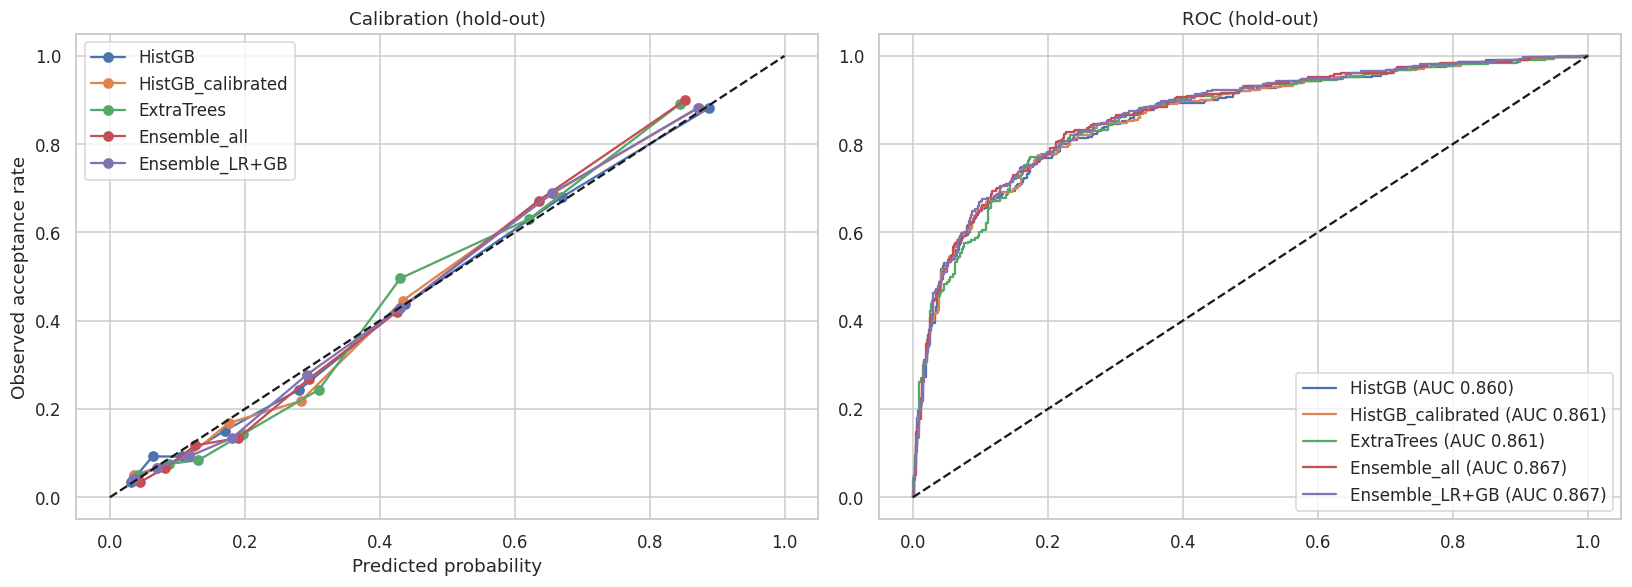

In [27]:
# Calibration & ROC on the hold-out for the top models – the cost rule relies on trustworthy probabilities
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for n in results.index[:5]:
    ph = clone(tuned[n]).fit(X_dev, y_dev).predict_proba(X_hold)[:, 1]
    fp, mp = calibration_curve(y_hold, ph, n_bins=8, strategy="quantile"); ax[0].plot(mp, fp, "o-", label=n)
    fpr, tpr, _ = roc_curve(y_hold, ph); ax[1].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_hold, ph):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_xlabel("Predicted probability"); ax[0].set_ylabel("Observed acceptance rate"); ax[0].set_title("Calibration (hold-out)"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (hold-out)"); ax[1].legend(); plt.tight_layout(); plt.show()

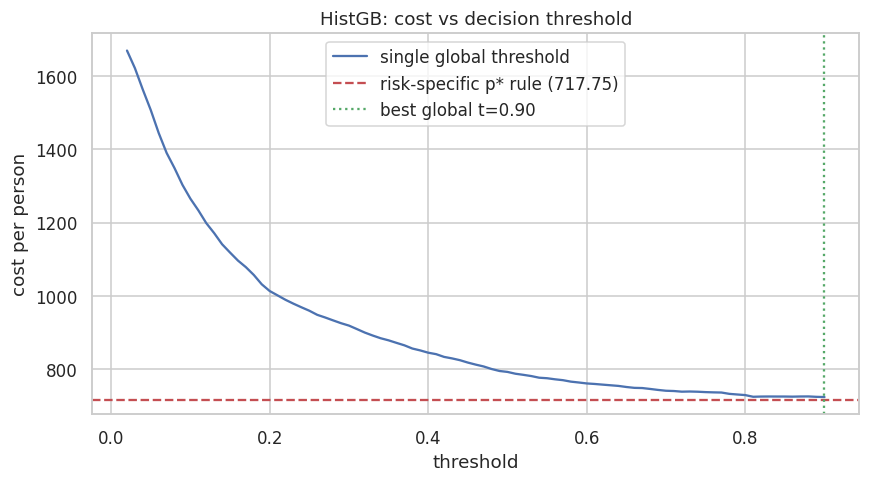

In [28]:
# Is the decision-rule better than the best single global threshold? (cost vs threshold curve, best model, OOF predictions)
best_name = results.index[0]
oof = cross_val_predict(tuned[best_name], X_dev, y_dev, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
ths = np.linspace(0.02, 0.9, 89)
curve = [total_cost(y_dev, (oof > t).astype(int), h_dev) / len(y_dev) for t in ths]
rule_cost = total_cost(y_dev, decide(oof, h_dev), h_dev) / len(y_dev)
plt.figure(figsize=(9, 4.5)); plt.plot(ths, curve, label="single global threshold"); plt.axhline(rule_cost, c="r", ls="--", label=f"risk-specific p* rule ({rule_cost:.2f})")
plt.axvline(ths[int(np.argmin(curve))], c="g", ls=":", label=f"best global t={ths[int(np.argmin(curve))]:.2f}"); plt.xlabel("threshold"); plt.ylabel("cost per person"); plt.title(f"{best_name}: cost vs decision threshold"); plt.legend(); plt.show()

### 5.1 Pre-processing / model validation of statistical significance

In [29]:
# Paired comparison of the best model against the others over the same 10 folds (are differences real or noise?)
b = fold_tables[best_name].cost.to_numpy()
rows = [(n, (fold_tables[n].cost.to_numpy() - b).mean(), stats.ttest_rel(fold_tables[n].cost.to_numpy(), b).pvalue) for n in results.index if n != best_name]
display(pd.DataFrame(rows, columns=["model", f"mean cost diff vs {best_name}", "paired t p-value"]).set_index("model").round(4))
print("Folds overlap in training data so p-values are optimistic; treat as indicative, not definitive.")

,mean cost diff vs HistGB,paired t p-value
model,,
HistGB_calibrated,0.2217,0.7490
ExtraTrees,0.3564,0.7506
Ensemble_all,0.5481,0.4422
Ensemble_LR+GB,0.5791,0.2656
RandomForest,0.8965,0.3296
LogReg,1.5473,0.0509
GradBoost,1.7748,0.0760
LogReg_calibrated,2.1220,0.0835


Folds overlap in training data so p-values are optimistic; treat as indicative, not definitive.


## 6. What drives acceptance? (model-based importance)

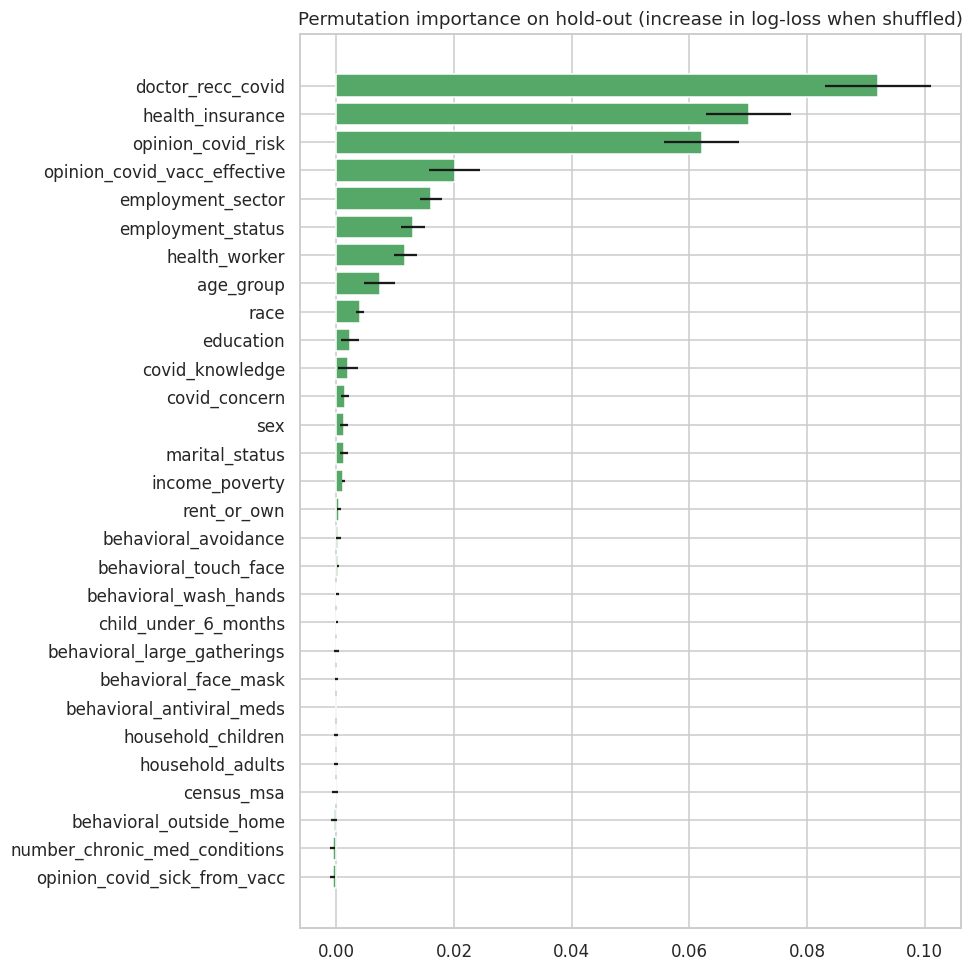

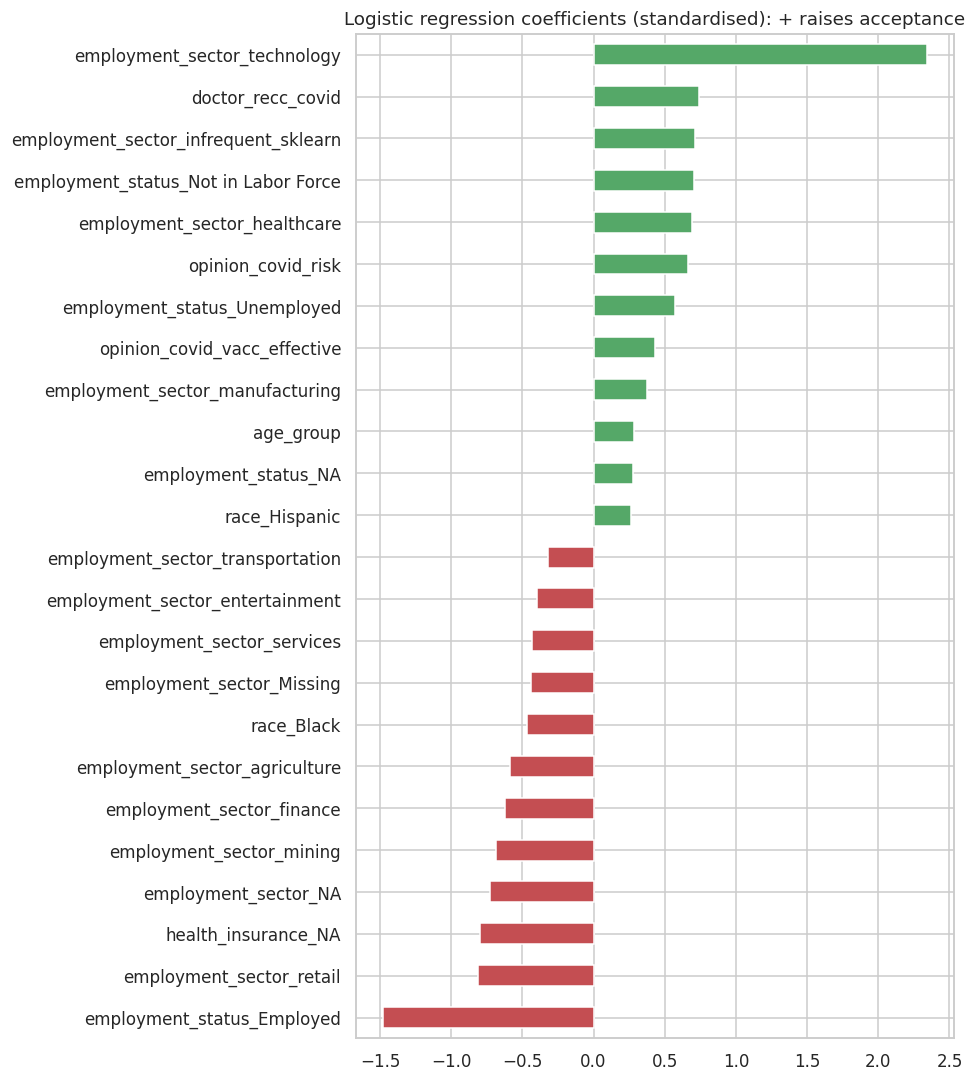

Combined ranking of variables affecting the target (lower rank_score = stronger evidence):


,cramers_v,mutual_info,perm_importance,rank_score
feature,,,,
doctor_recc_covid,0.4302,0.0883,0.0921,1.0000
opinion_covid_risk,0.3789,0.0735,0.0621,2.3333
opinion_covid_vacc_effective,0.3307,0.0573,0.0201,3.3333
employment_sector,0.2234,0.0271,0.0160,4.6667
health_worker,0.1953,0.0180,0.0117,6.0000
health_insurance,0.2995,0.0030,0.0701,7.6667
covid_knowledge,0.1678,0.0142,0.0020,8.0000
covid_concern,0.1320,0.0093,0.0015,9.0000
education,0.1112,0.0067,0.0023,9.6667


In [30]:
fit_best = clone(tuned["Ensemble_all"]).fit(X_dev, y_dev)
pi = permutation_importance(fit_best, X_hold, y_hold, scoring="neg_log_loss", n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"perm_importance": pi.importances_mean, "sd": pi.importances_std}, index=X_hold.columns).sort_values("perm_importance")
plt.figure(figsize=(9, 9)); plt.barh(imp.index, imp.perm_importance, xerr=imp.sd, color="#55a868"); plt.title("Permutation importance on hold-out (increase in log-loss when shuffled)"); plt.tight_layout(); plt.show()

# Direction of effect from the (tuned) logistic regression
lr = clone(tuned["LogReg"]).fit(X_dev, y_dev)
names = lr[0][-1].get_feature_names_out(); coef = pd.Series(lr[-1].coef_[0], index=[n.split("__")[-1] for n in names]).sort_values()
plt.figure(figsize=(9, 10))
sel = pd.concat([coef.head(12), coef.tail(12)]); sel.plot.barh(color=np.where(sel > 0, "#55a868", "#c44e52")); plt.title("Logistic regression coefficients (standardised): + raises acceptance"); plt.tight_layout(); plt.show()

# Combined evidence table: statistical association vs model importance
combo = assoc[["cramers_v", "mutual_info"]].join(imp["perm_importance"]).dropna()
combo["rank_score"] = combo.rank(ascending=False).mean(axis=1)
print("Combined ranking of variables affecting the target (lower rank_score = stronger evidence):")
display(combo.sort_values("rank_score").round(4).head(12))

## 7. Robustness of the cost assumptions (sensitivity analysis)
The brief asks to cross-check hospitalisation assumptions with different AIs. Different assistants give different ranges, so we re-score the same hold-out predictions under alternative parameter scenarios. If the model ranking and the savings vs naive strategies are stable, the submission is robust to the assumption uncertainty.

,order_nobody,order_all,LogReg,HistGB,Ensemble_all,GradBoost,best_naive,saving_vs_best_naive_%
scenario,,,,,,,,
base (grounded),744.41,1710.46,741.09,746.32,742.60,743.16,744.41,0.24
cheaper vaccine (750),499.40,960.46,490.34,487.97,489.64,491.72,499.40,1.95
pricier vaccine (3000),1234.43,3210.46,1232.13,1232.72,1233.46,1232.64,1234.43,0.08
cheaper hospital (20k),614.11,1602.67,613.23,613.32,613.99,613.28,614.11,0.02
costlier hospital (80k),986.39,1910.66,970.16,964.50,963.01,970.29,986.39,2.37
weak vaccine (VE 30%),744.41,1725.11,744.22,743.79,742.15,743.26,744.41,0.30
stronger vaccine (VE 70%),744.41,1686.06,731.14,731.51,731.04,735.20,744.41,1.80
risk x0.5,617.22,1605.23,616.06,616.36,616.73,616.32,617.22,0.08
risk x2,998.80,1920.93,980.68,975.93,979.28,983.44,998.80,1.95


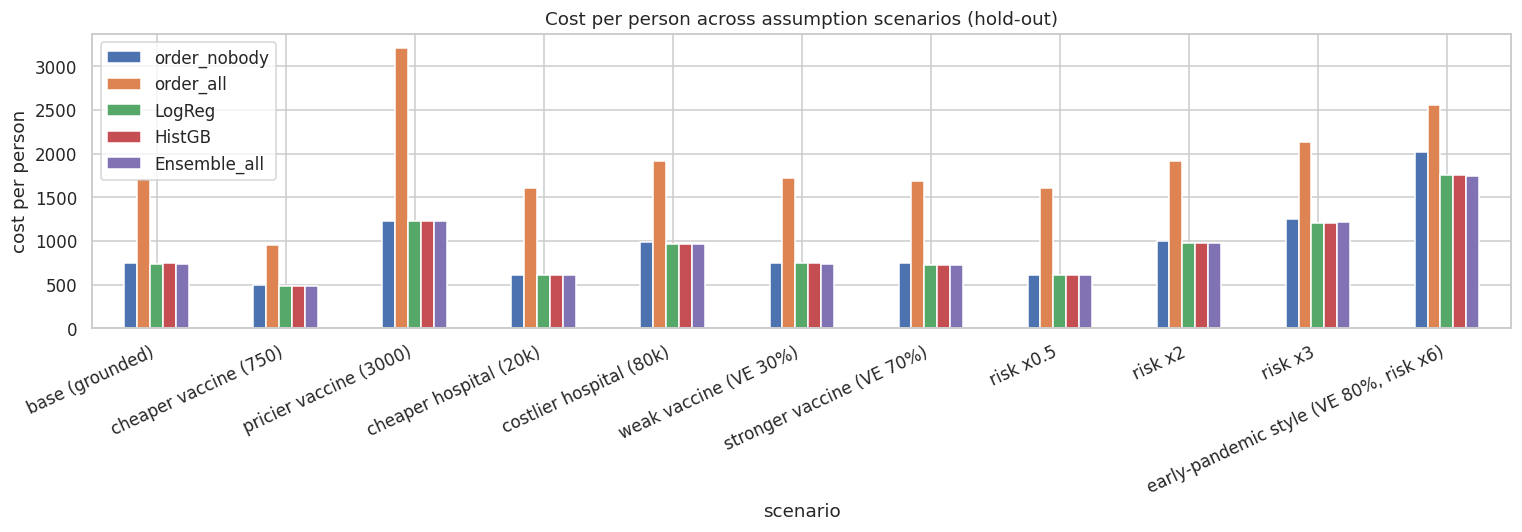

In [31]:
scen = {"base (grounded)":         dict(C_V=1500, C_H=41000, VE=BASE["VE"], hm=1.0),
        "cheaper vaccine (750)":  dict(C_V=750,  C_H=41000, VE=BASE["VE"], hm=1.0),
        "pricier vaccine (3000)": dict(C_V=3000, C_H=41000, VE=BASE["VE"], hm=1.0),
        "cheaper hospital (20k)": dict(C_V=1500, C_H=20000, VE=BASE["VE"], hm=1.0),
        "costlier hospital (80k)":dict(C_V=1500, C_H=80000, VE=BASE["VE"], hm=1.0),
        "weak vaccine (VE 30%)":  dict(C_V=1500, C_H=41000, VE=0.30, hm=1.0),
        "stronger vaccine (VE 70%)": dict(C_V=1500, C_H=41000, VE=0.70, hm=1.0),
        "risk x0.5":              dict(C_V=1500, C_H=41000, VE=BASE["VE"], hm=0.5),
        "risk x2":                dict(C_V=1500, C_H=41000, VE=BASE["VE"], hm=2.0),
        "risk x3":                dict(C_V=1500, C_H=41000, VE=BASE["VE"], hm=3.0),
        "early-pandemic style (VE 80%, risk x6)": dict(C_V=1500, C_H=41000, VE=0.80, hm=6.0)}
fits = {n: clone(tuned[n]).fit(X_dev, y_dev).predict_proba(X_hold)[:, 1] for n in tuned}
rows = []
for s, a in scen.items():
    kw = dict(C_V=a["C_V"], C_H=a["C_H"], VE=a["VE"]); hh = np.clip(h_hold * a["hm"], 0, .5)
    row = {"scenario": s, "order_nobody": total_cost(y_hold, 0*y_hold, hh, **kw)/len(y_hold), "order_all": total_cost(y_hold, 0*y_hold+1, hh, **kw)/len(y_hold)}
    for n in ["LogReg", "HistGB", "Ensemble_all", "GradBoost"]: row[n] = total_cost(y_hold, decide(fits[n], hh, **kw), hh, **kw)/len(y_hold)
    row["best_naive"] = min(row["order_nobody"], row["order_all"]); row["saving_vs_best_naive_%"] = 100 * (row["best_naive"] - row["Ensemble_all"]) / row["best_naive"]
    rows.append(row)
sens = pd.DataFrame(rows).set_index("scenario"); display(sens.round(2))
sens[["order_nobody", "order_all", "LogReg", "HistGB", "Ensemble_all"]].plot.bar(figsize=(14, 5)); plt.ylabel("cost per person"); plt.title("Cost per person across assumption scenarios (hold-out)"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

## 8. Final selection and the 5 submission files
Ranking criterion: **lowest mean CV cost per person** on the development set (hold-out cost used as a sanity check / tie-breaker, since cost differences between the top models are within one standard deviation of fold noise). Each chosen model is **re-fitted on all labelled data** (dev + hold-out) and predicts the test set; the decision rule *order iff p > p\**_i* turns probabilities into the binary file requested.

In [32]:
GROUP_NUMBER = 0   # <- set your group number
top5 = list(results.index[:5])
final_probs, files = {}, []
os.makedirs("submissions", exist_ok=True)
for rank, name in enumerate(top5, start=1):
    m = clone(tuned[name]).fit(X, y)                       # refit on ALL labelled data
    p = m.predict_proba(X_test)[:, 1]; final_probs[name] = p
    pred = decide(p, h_test)
    sub = pd.DataFrame({ID: test[ID], TARGET: pred})       # columns: respondent_id + predicted target (vaccine)
    fn = f"submissions/challenge_submission_group_{GROUP_NUMBER}_order_{rank}.csv"; sub.to_csv(fn, index=False); files.append(fn)
    print(f"#{rank} {name:18s} CV cost/person={results.loc[name,'cv_cost_mean']:.2f} ± {results.loc[name,'cv_cost_sd']:.2f} | hold-out={results.loc[name,'hold_cost']:.2f} | orders {pred.mean()*100:.1f}% -> {fn}")

# sanity checks on the files
for fn in files:
    s = pd.read_csv(fn); assert list(s.columns) == [ID, TARGET] and len(s) == len(test) and s[ID].equals(test[ID]) and s[TARGET].isin([0, 1]).all()
print("\nAll files valid. Agreement between submissions (share of identical decisions):")
agree = pd.DataFrame([[ (pd.read_csv(a)[TARGET] == pd.read_csv(b)[TARGET]).mean() for b in files] for a in files], index=[f"#{i}" for i in range(1, 6)], columns=[f"#{i}" for i in range(1, 6)])
display(agree.round(3))

#1 HistGB             CV cost/person=718.20 ± 5.78 | hold-out=746.32 | orders 4.7% -> submissions/challenge_submission_group_0_order_1.csv
#2 HistGB_calibrated  CV cost/person=718.42 ± 5.43 | hold-out=741.40 | orders 4.3% -> submissions/challenge_submission_group_0_order_2.csv
#3 ExtraTrees         CV cost/person=718.56 ± 5.27 | hold-out=739.86 | orders 3.6% -> submissions/challenge_submission_group_0_order_3.csv
#4 Ensemble_all       CV cost/person=718.75 ± 5.33 | hold-out=742.60 | orders 3.7% -> submissions/challenge_submission_group_0_order_4.csv
#5 Ensemble_LR+GB     CV cost/person=718.78 ± 5.07 | hold-out=744.02 | orders 4.3% -> submissions/challenge_submission_group_0_order_5.csv

All files valid. Agreement between submissions (share of identical decisions):


,#1,#2,#3,#4,#5
#1,1.000,0.996,0.986,0.989,0.993
#2,0.996,1.000,0.988,0.992,0.995
#3,0.986,0.988,1.000,0.993,0.987
#4,0.989,0.992,0.993,1.000,0.993
#5,0.993,0.995,0.987,0.993,1.000


In [33]:
# Expected cost on the test set (no labels available -> use calibrated probabilities): our estimate of what the teaching team will measure
exp = []
for name in top5:
    p = final_probs[name]; d = decide(p, h_test)
    exp_cost = (d * (BASE["C_V"] + BASE["C_H"]*h_test*(1 - p*BASE["VE"])) + (1-d) * (p*BASE["C_V"] + BASE["C_H"]*h_test)).mean()
    exp.append((name, exp_cost))
print(pd.DataFrame(exp, columns=["model", "expected test cost per person"]).round(2).to_string(index=False))
print("Naive references (expected, using best model probs): order nobody = %.2f, order everybody = %.2f" % (
      (final_probs[top5[0]]*BASE["C_V"] + BASE["C_H"]*h_test).mean(), (BASE["C_V"] + BASE["C_H"]*h_test*(1 - final_probs[top5[0]]*BASE["VE"])).mean()))

            model  expected test cost per person
           HistGB                         739.43
HistGB_calibrated                         741.46
       ExtraTrees                         736.99
     Ensemble_all                         739.40
   Ensemble_LR+GB                         739.51
Naive references (expected, using best model probs): order nobody = 746.67, order everybody = 1703.24


In [34]:
C_V, C_H, VE = BASE["C_V"], BASE["C_H"], BASE["VE"]

def expected_total(p, d, h):
    return float((d * (C_V + C_H*h*(1 - p*VE)) + (1-d) * (p*C_V + C_H*h)).sum())

rows = []
for rank, name in enumerate(top5, start=1):
    p = final_probs[name]; d = decide(p, h_test)
    rows.append({"submission_order": rank, "model": name,
                 "vaccines_ordered": int(d.sum()),
                 "expected_total_cost": expected_total(p, d, h_test)})

p0 = final_probs[top5[0]]
rows.append({"submission_order": "-", "model": "order nobody (reference)", "vaccines_ordered": 0,
             "expected_total_cost": expected_total(p0, np.zeros(len(p0), int), h_test)})
rows.append({"submission_order": "-", "model": "order everybody (reference)", "vaccines_ordered": len(p0),
             "expected_total_cost": expected_total(p0, np.ones(len(p0), int), h_test)})

final_tbl = (pd.DataFrame(rows)
             .sort_values("expected_total_cost", ascending=True)   # lowest cost first
             .reset_index(drop=True))
final_tbl["per_person"] = final_tbl["expected_total_cost"] / len(test)
final_tbl["expected_total_cost"] = final_tbl["expected_total_cost"].round(0).astype(int)

print(f"Grounded scenario: VE={VE:.0%}, C_V={C_V:,.0f}, C_H={C_H:,.0f}, test people={len(test):,}")
print(final_tbl.round(2).to_string(index=False))
best = final_tbl.iloc[0]
print(f"\nLowest expected total: {best['model']} = {best['expected_total_cost']:,}")

Grounded scenario: VE=45%, C_V=1,500, C_H=41,000, test people=4,749
submission_order                       model  vaccines_ordered  expected_total_cost  per_person
               3                  ExtraTrees               172              3499977      736.99
               4                Ensemble_all               174              3511419      739.40
               1                      HistGB               221              3511559      739.43
               5              Ensemble_LR+GB               202              3511943      739.51
               2           HistGB_calibrated               206              3521182      741.46
               -    order nobody (reference)                 0              3545926      746.67
               - order everybody (reference)              4749              8088690     1703.24

Lowest expected total: ExtraTrees = 3,499,977


## 9. Critical evaluation and conclusions
* **Scenario used (grounded):** vaccine 1,500, hospitalisation 41,000, vaccine effectiveness 45 % (CDC 2024-25 interim estimate), hospitalisation risk per infection of about 0.08 % (age 18-34) to 1.2 % (65+) with +75 % per chronic condition, behaviours neutral. Infection is 100 % for everyone.
* **Results (grounded run).** The ordering bar P(accept) > 1500 / (1500 + 41000 x h x VE) ranges from 0.68 to 0.99 across people, so the models order a vaccine for only ~3-5 % of people. Expected test-set total is about 3.5M (4749 people, ~737-741 per person; order nobody ~747, order everybody ~1,703). On the hold-out: order nobody 744, models 740-746, oracle 700 per person.
* **Saving over the best naive strategy is only ~0.2 %.** With a 45 % effective vaccine and ~0.1-1.2 % risk per infection, a 1,500 vaccine rarely pays for itself, so the best decision is almost always 'do not order'. The saving rises to ~2 % with VE 70 % or risk x2, ~3 % at risk x3, and ~14 % only in an early-pandemic scenario (VE 80 %, risk x6).
* **Most of the cost is fixed.** About one third of people accept and are paid or given the vaccine price whatever we decide (~2.3M of the total).
* **Top models are statistically tied.** CV costs differ by far less than the fold-to-fold SD; rank by mean CV cost with the hold-out as a sanity check.
* **Drivers of acceptance.** Doctor recommendation, perceived risk and perceived effectiveness dominate. Behaviours add little once these are included.
* **Limitations.** Hospitalisation risk, vaccine effectiveness and the 35 % infection share used in the conversion are assumptions and could each be off by a factor of 2 or more; the data has no outcomes. The hold-out (~950 rows) is small, so its cost estimates are noisy. Re-run after replacing the numbers with your team's consensus.
